In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# 노트북 폴더 또는 프로젝트 루트 어느 위치에서 실행해도 데이터 경로를 찾습니다.
DATA_DIR = next(p for p in [Path.cwd(), Path.cwd() / '프로젝트1조'] if (p / 'cs-training.csv').exists())
OUTPUT_DIR = DATA_DIR / 'graphs'
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

train = pd.read_csv(DATA_DIR / 'cs-training.csv', index_col=0)
test = pd.read_csv(DATA_DIR / 'cs-test.csv', index_col=0)
submission = pd.read_csv(DATA_DIR / 'sampleEntry.csv')
TARGET = 'SeriousDlqin2yrs'
FEATURES = [c for c in train.columns if c != TARGET]
print('학습:', train.shape, '/ 예측용:', test.shape, '/ 제출 예시:', submission.shape)
print('학습 정답 분포:', train[TARGET].value_counts().to_dict())
print('예측용 정답 빈 값:', test[TARGET].isna().sum())
display(train.head(3))
display(pd.DataFrame({'자료형': train.dtypes, '학습 결측(%)': train.isna().mean().mul(100).round(2), '예측용 결측(%)': test.isna().mean().mul(100).round(2)}))
try:
    dictionary = pd.read_excel(DATA_DIR / 'Data Dictionary.xls', header=1)
    display(dictionary)
except ImportError:
    print('Data Dictionary.xls: 구형 Excel 읽기 엔진(xlrd)이 없어 별도 확인이 필요합니다.')

# 원본은 유지합니다. 아래 범위 제한은 그래프 표시만을 위한 것으로 학습 전처리가 아닙니다.
def finish(fig, filename):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

학습: (150000, 11) / 예측용: (101503, 11) / 제출 예시: (101503, 2)
학습 정답 분포: {0: 139974, 1: 10026}
예측용 정답 빈 값: 101503


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0


,자료형,학습 결측(%),예측용 결측(%)
SeriousDlqin2yrs,int64,0.00,100.00
RevolvingUtilizationOfUnsecuredLines,float64,0.00,0.00
age,int64,0.00,0.00
NumberOfTime30-59DaysPastDueNotWorse,int64,0.00,0.00
DebtRatio,float64,0.00,0.00
MonthlyIncome,float64,19.82,19.81
NumberOfOpenCreditLinesAndLoans,int64,0.00,0.00
NumberOfTimes90DaysLate,int64,0.00,0.00
NumberRealEstateLoansOrLines,int64,0.00,0.00
NumberOfTime60-89DaysPastDueNotWorse,int64,0.00,0.00


,Variable Name,Description,Type
0,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
1,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
2,age,Age of borrower in years,integer
3,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
4,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
5,MonthlyIncome,Monthly income,real
6,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
7,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
8,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer
9,NumberOfTime60-89DaysPastDueNotWorse,Number of times borrower has been 60-89 days p...,integer


In [14]:
# 변수 설명서를 읽고, 그래프에서 쓸 짧은 한글 이름을 지정합니다.
dictionary = pd.read_excel(DATA_DIR / 'Data Dictionary.xls', header=1)
display(dictionary.dropna(how='all'))
NAMES = {
    'RevolvingUtilizationOfUnsecuredLines': '신용한도 사용 비율',
    'age': '나이',
    'NumberOfTime30-59DaysPastDueNotWorse': '30~59일 연체 횟수',
    'DebtRatio': '부채 비율',
    'MonthlyIncome': '월소득',
    'NumberOfOpenCreditLinesAndLoans': '신용계좌·대출 수',
    'NumberOfTimes90DaysLate': '90일 이상 연체 횟수',
    'NumberRealEstateLoansOrLines': '부동산 대출 수',
    'NumberOfTime60-89DaysPastDueNotWorse': '60~89일 연체 횟수',
    'NumberOfDependents': '부양가족 수',
    TARGET: '심각한 연체 여부'
}
# 분포 관찰용: 원본은 수정하지 않고 파생 열만 별도 표에 생성합니다.
eda = train.copy()
eda['연체 여부'] = eda[TARGET].map({0: '연체 없음', 1: '연체 있음'})
eda['나이대'] = pd.cut(eda['age'], [0, 30, 40, 50, 60, 70, np.inf], right=False,
                      labels=['30세 미만', '30대', '40대', '50대', '60대', '70세 이상'])
print('나이 0 이하:', (train['age'] <= 0).sum())
late_cols = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']
print('연체 횟수의 96/98 값은 의미 확인이 필요한 특이값입니다.')
print(train[late_cols].isin([96, 98]).sum().rename(index=NAMES).to_string())

,Variable Name,Description,Type
0,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
1,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
2,age,Age of borrower in years,integer
3,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
4,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
5,MonthlyIncome,Monthly income,real
6,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
7,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
8,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer
9,NumberOfTime60-89DaysPastDueNotWorse,Number of times borrower has been 60-89 days p...,integer


나이 0 이하: 1
연체 횟수의 96/98 값은 의미 확인이 필요한 특이값입니다.
30~59일 연체 횟수    269
60~89일 연체 횟수    269
90일 이상 연체 횟수    269


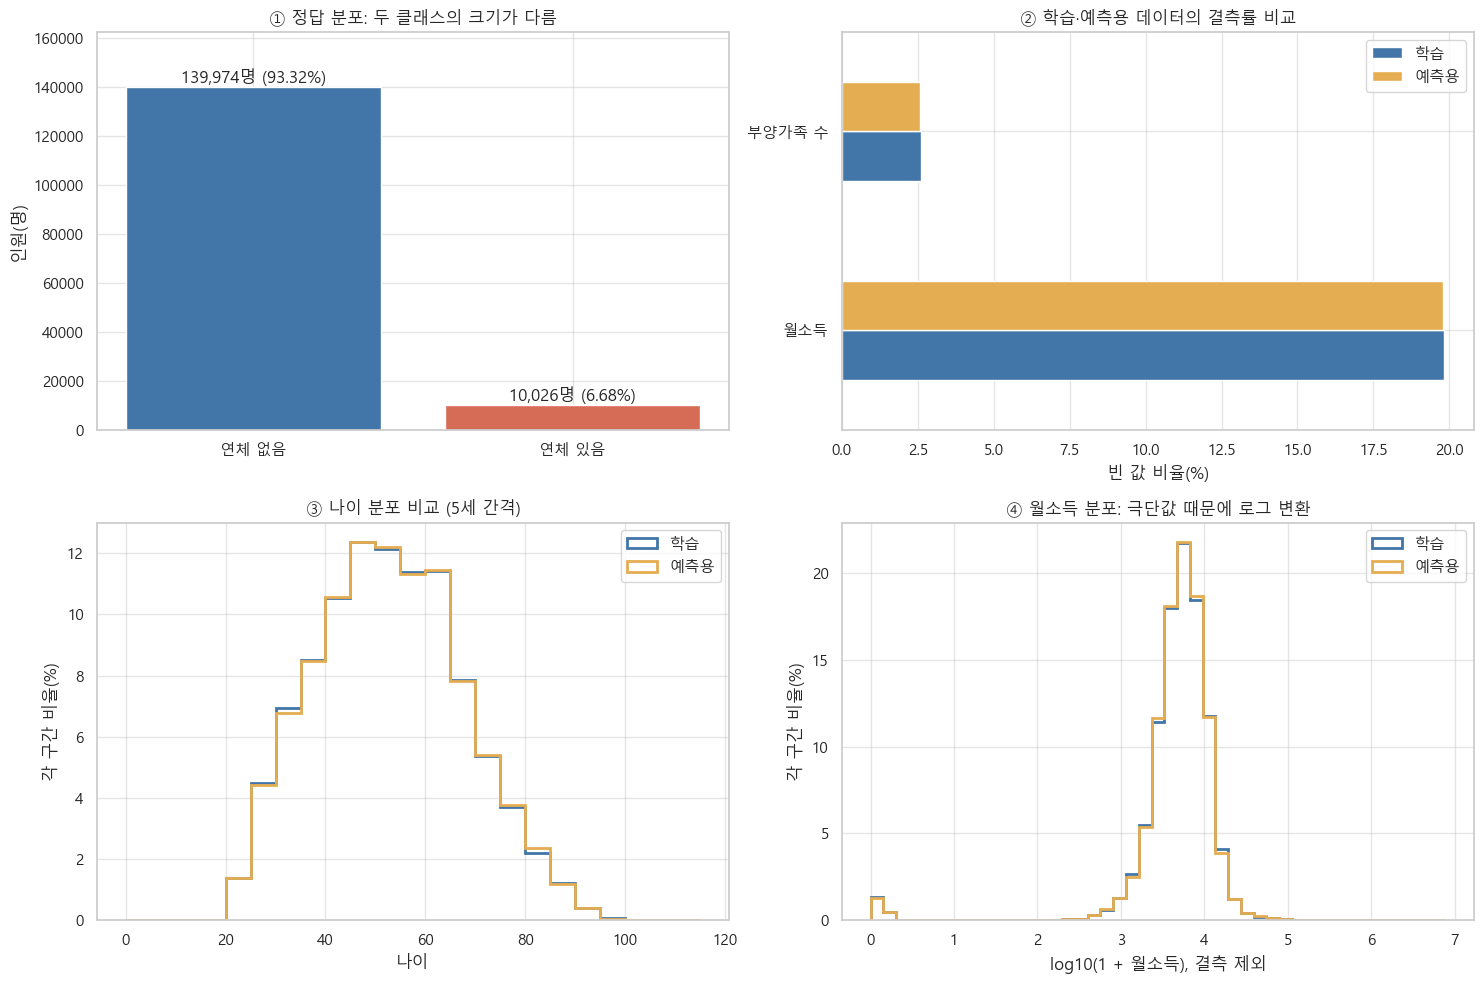

In [6]:
# 1~4: 데이터 규모, 빈 값, 나이, 소득의 분포
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
counts = train[TARGET].value_counts().reindex([0, 1])
bars = axes[0, 0].bar(['연체 없음', '연체 있음'], counts, color=['#4275a8', '#d66b56'])
for b, n in zip(bars, counts):
    axes[0, 0].text(b.get_x() + b.get_width()/2, n, f'{n:,}명 ({n/len(train):.2%})', ha='center', va='bottom')
axes[0, 0].set_ylim(0, counts.max()*1.16)
axes[0, 0].set(title='① 정답 분포: 두 클래스의 크기가 다름', ylabel='인원(명)')

missing = pd.DataFrame({'학습': train[FEATURES].isna().mean()*100,
                        '예측용': test[FEATURES].isna().mean()*100})
missing = missing.loc[missing.max(axis=1) > 0].rename(index=NAMES)
missing.plot.barh(ax=axes[0, 1], color=['#4275a8', '#e5ad52'])
axes[0, 1].set(title='② 학습·예측용 데이터의 결측률 비교', xlabel='빈 값 비율(%)', ylabel='')

age_bins = np.arange(0, 116, 5)
for frame, name, color in [(train, '학습', '#4275a8'), (test, '예측용', '#e5ad52')]:
    axes[1, 0].hist(frame['age'], bins=age_bins, weights=np.ones(len(frame))/len(frame)*100,
                    histtype='step', linewidth=2, label=name, color=color)
axes[1, 0].set(title='③ 나이 분포 비교 (5세 간격)', xlabel='나이', ylabel='각 구간 비율(%)')
axes[1, 0].legend()

income_bins = np.linspace(0, np.log10(1 + max(train['MonthlyIncome'].max(), test['MonthlyIncome'].max())), 46)
for frame, name, color in [(train, '학습', '#4275a8'), (test, '예측용', '#e5ad52')]:
    income = frame['MonthlyIncome'].dropna()
    axes[1, 1].hist(np.log10(1+income), bins=income_bins, weights=np.ones(len(income))/len(income)*100,
                    histtype='step', linewidth=2, label=name, color=color)
axes[1, 1].set(title='④ 월소득 분포: 극단값 때문에 로그 변환', xlabel='log10(1 + 월소득), 결측 제외', ylabel='각 구간 비율(%)')
axes[1, 1].legend()
finish(fig, '01_데이터개요.png')


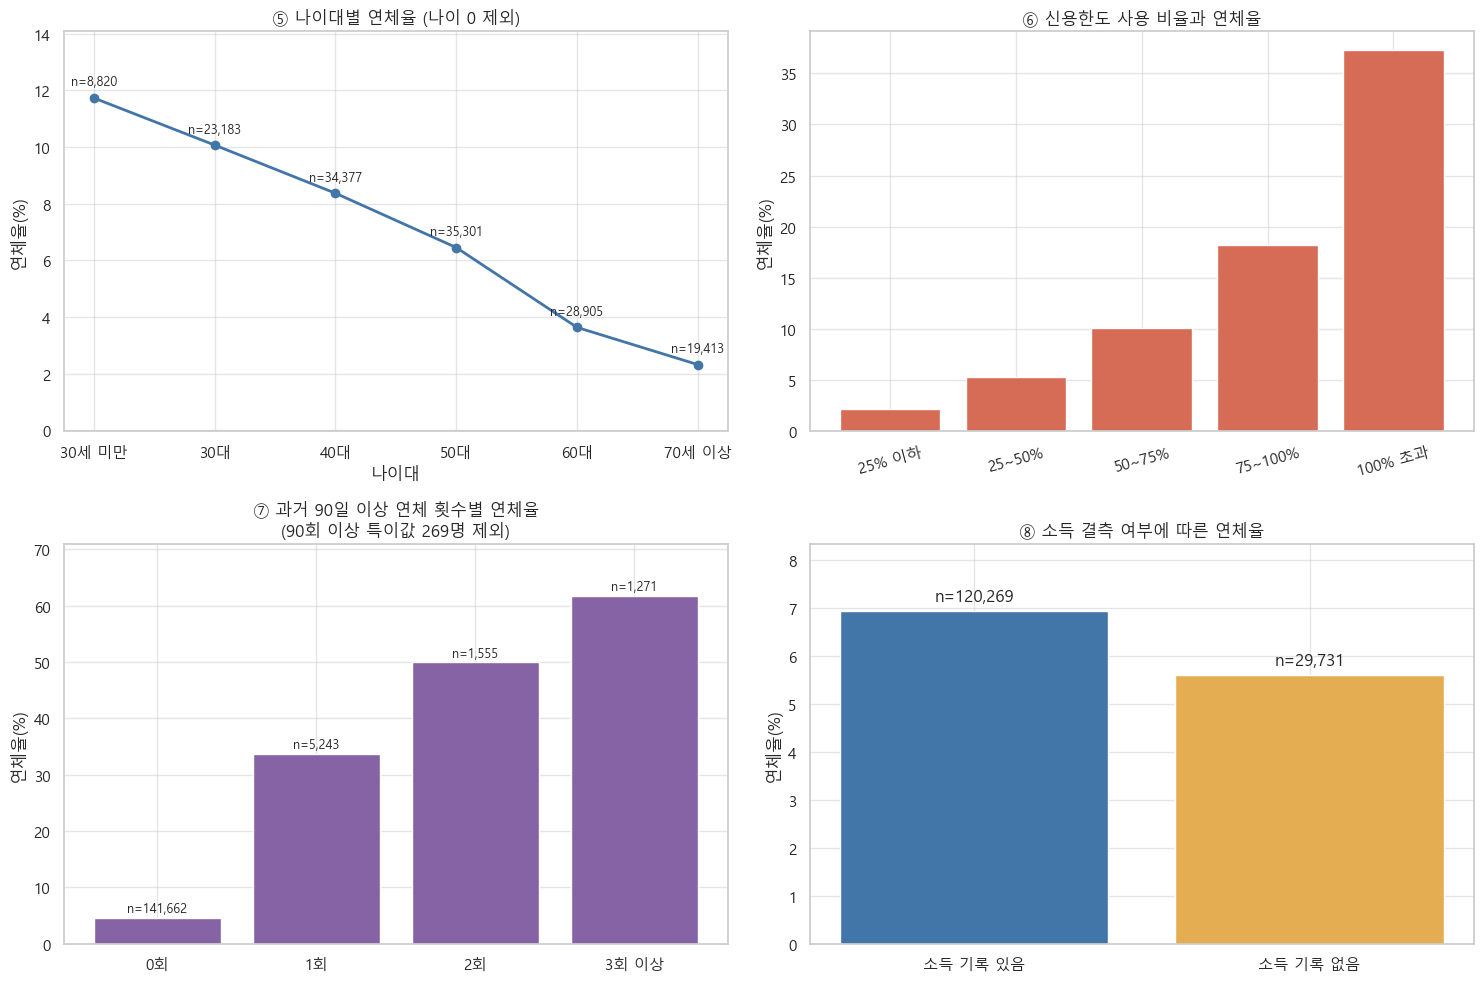

In [4]:
# 5~8: 각 그룹의 연체율. 인과관계가 아니라 관찰된 관계입니다.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
age_stats = eda.loc[eda['age'] > 0].groupby('나이대', observed=True)[TARGET].agg(['mean', 'size'])
axes[0, 0].plot(age_stats.index.astype(str), age_stats['mean']*100, 'o-', color='#4275a8', linewidth=2)
for i, row in enumerate(age_stats.itertuples()):
    axes[0, 0].annotate(f'n={row.size:,}', (i, row.mean*100), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
axes[0, 0].set(title='⑤ 나이대별 연체율 (나이 0 제외)', ylabel='연체율(%)', xlabel='나이대')
axes[0, 0].margins(y=0.25)

util = train['RevolvingUtilizationOfUnsecuredLines']
eda['사용률 구간'] = pd.cut(util, [-np.inf, .25, .5, .75, 1, np.inf],
                           labels=['25% 이하', '25~50%', '50~75%', '75~100%', '100% 초과'])
u = eda.groupby('사용률 구간', observed=True)[TARGET].agg(['mean', 'size'])
axes[0, 1].bar(u.index.astype(str), u['mean']*100, color='#d66b56')
axes[0, 1].set(title='⑥ 신용한도 사용 비율과 연체율', ylabel='연체율(%)')
axes[0, 1].tick_params(axis='x', labelrotation=15)

late = train['NumberOfTimes90DaysLate']
valid_late = late < 90
late_group = late.loc[valid_late].clip(upper=3).map({0:'0회', 1:'1회', 2:'2회', 3:'3회 이상'})
late_stats = train.loc[valid_late].groupby(late_group)[TARGET].agg(['mean', 'size']).reindex(['0회','1회','2회','3회 이상'])
axes[1, 0].bar(late_stats.index, late_stats['mean']*100, color='#8563a4')
for i, row in enumerate(late_stats.itertuples()):
    axes[1, 0].text(i, row.mean*100+1, f'n={row.size:,}', ha='center', fontsize=9)
axes[1, 0].set(title=f'⑦ 과거 90일 이상 연체 횟수별 연체율\n(90회 이상 특이값 {(~valid_late).sum():,}명 제외)', ylabel='연체율(%)')
axes[1, 0].margins(y=0.15)

income_missing = train.groupby(train['MonthlyIncome'].isna())[TARGET].agg(['mean','size'])
axes[1, 1].bar(['소득 기록 있음', '소득 기록 없음'], income_missing['mean']*100, color=['#4275a8','#e5ad52'])
for i, row in enumerate(income_missing.itertuples()):
    axes[1, 1].text(i, row.mean*100+0.2, f'n={row.size:,}', ha='center')
axes[1, 1].set(title='⑧ 소득 결측 여부에 따른 연체율', ylabel='연체율(%)')
axes[1, 1].margins(y=0.2)
finish(fig, '02_그룹별연체율.png')


소득 상자그림 제외: 결측 29731 / 99백분위 초과 1168 / 상한 25000.0


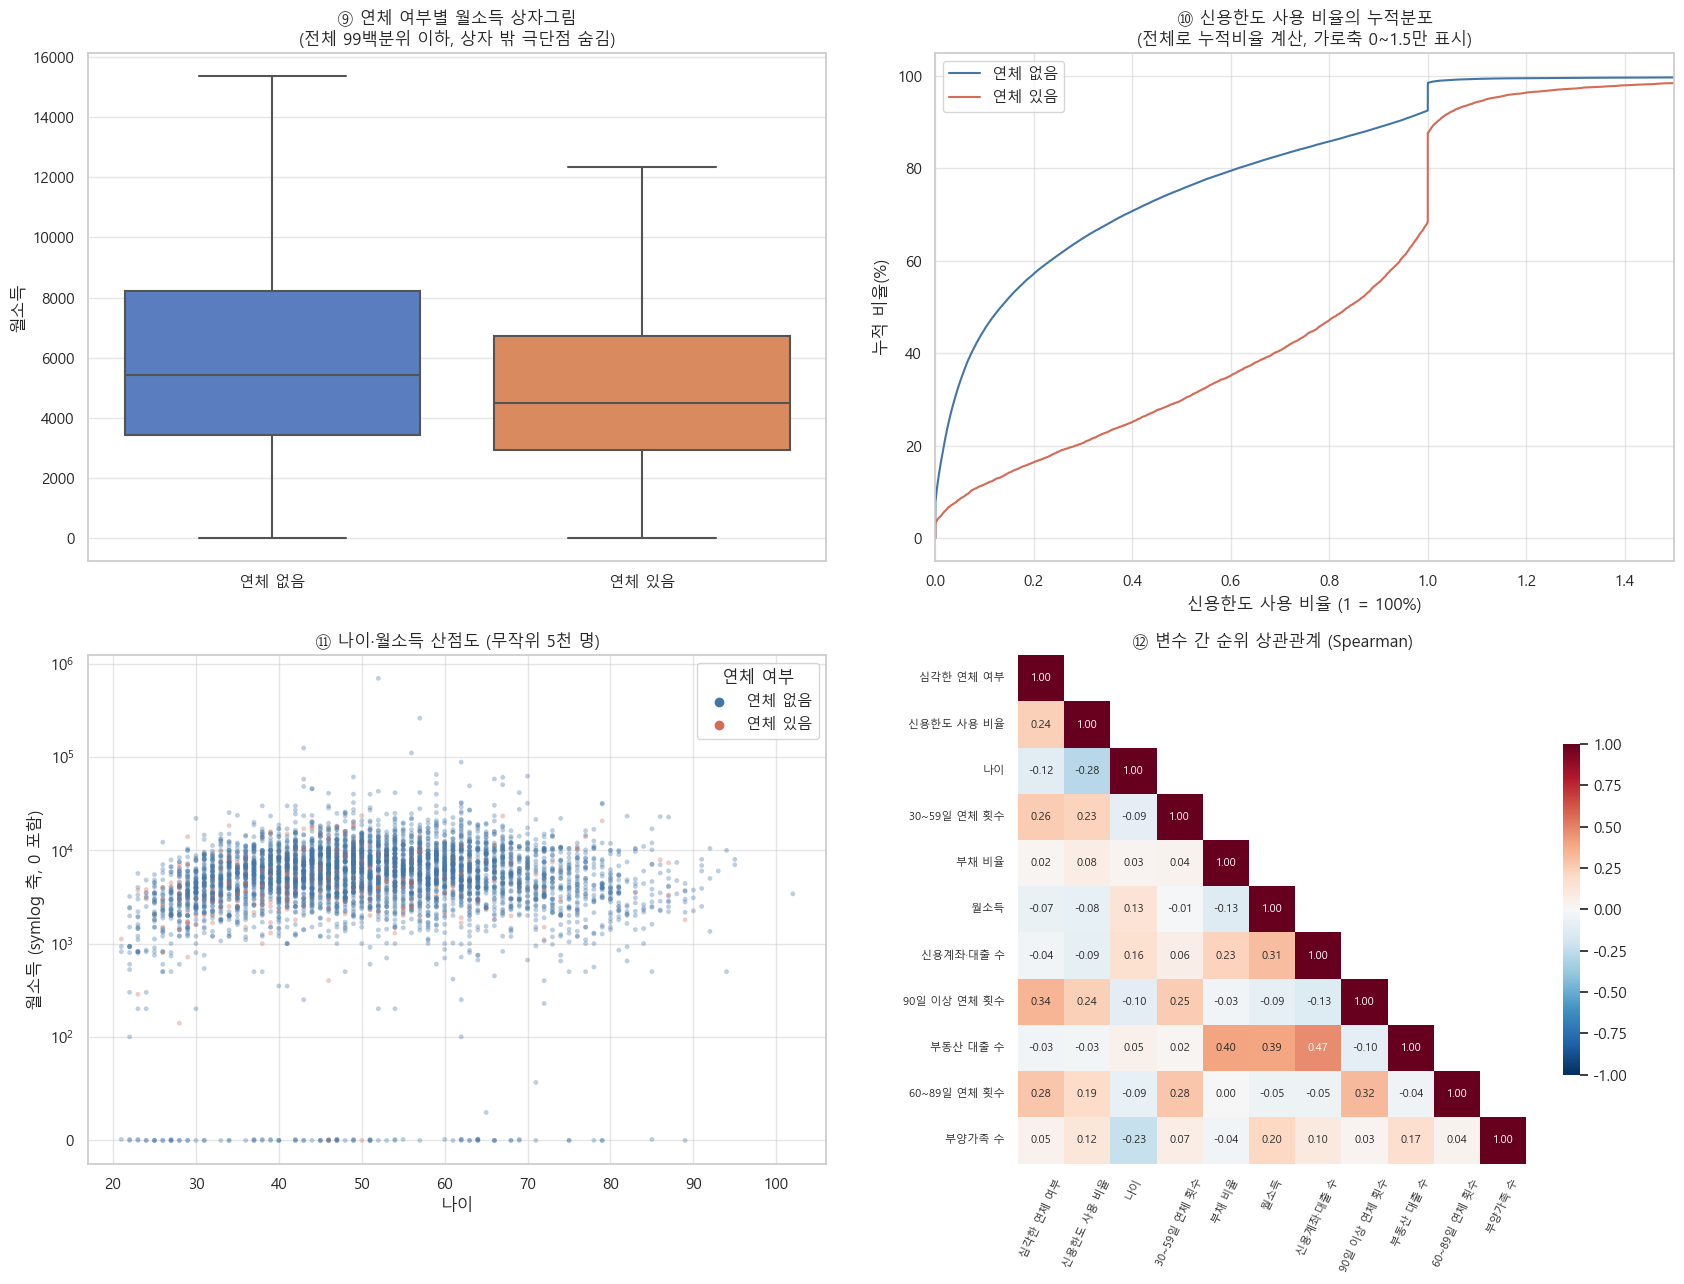

In [5]:
# 9~12: 상자그림, 누적분포, 산점도, 상관관계
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
income_limit = train['MonthlyIncome'].quantile(.99)
box_data = eda.loc[eda['MonthlyIncome'].le(income_limit)]
sns.boxplot(data=box_data, x='연체 여부', y='MonthlyIncome', order=['연체 없음','연체 있음'], showfliers=False, ax=axes[0, 0])
axes[0, 0].set(title=f'⑨ 연체 여부별 월소득 상자그림\n(전체 99백분위 이하, 상자 밖 극단점 숨김)', xlabel='', ylabel='월소득')
print('소득 상자그림 제외: 결측', train['MonthlyIncome'].isna().sum(),
      '/ 99백분위 초과', train['MonthlyIncome'].gt(income_limit).sum(), '/ 상한', round(income_limit, 2))

for label, color in [('연체 없음','#4275a8'), ('연체 있음','#d66b56')]:
    values = eda.loc[eda['연체 여부'].eq(label), 'RevolvingUtilizationOfUnsecuredLines'].sort_values().to_numpy()
    axes[0, 1].plot(values, np.arange(1, len(values)+1)/len(values)*100, label=label, color=color)
axes[0, 1].set_xlim(0, 1.5)
axes[0, 1].set(title='⑩ 신용한도 사용 비율의 누적분포\n(전체로 누적비율 계산, 가로축 0~1.5만 표시)', xlabel='신용한도 사용 비율 (1 = 100%)', ylabel='누적 비율(%)')
axes[0, 1].legend()

points = eda.loc[eda['MonthlyIncome'].notna() & eda['age'].gt(0)].sample(n=5000, random_state=42)
sns.scatterplot(data=points, x='age', y='MonthlyIncome', hue='연체 여부',
                hue_order=['연체 없음','연체 있음'], palette=['#4275a8','#d66b56'],
                s=12, alpha=.35, linewidth=0, ax=axes[1, 0])
axes[1, 0].set_yscale('symlog', linthresh=100)
axes[1, 0].set(title='⑪ 나이·월소득 산점도 (무작위 5천 명)', xlabel='나이', ylabel='월소득 (symlog 축, 0 포함)')

# Spearman: 값 자체보다 순위의 관계. 상관관계는 인과관계를 뜻하지 않습니다.
corr = train.corr(method='spearman').rename(index=NAMES, columns=NAMES)
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap='RdBu_r',
            vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', annot_kws={'size':8},
            square=True, cbar_kws={'shrink':.65}, ax=axes[1, 1])
axes[1, 1].set_title('⑫ 변수 간 순위 상관관계 (Spearman)')
axes[1, 1].tick_params(axis='x', labelrotation=65, labelsize=8)
axes[1, 1].tick_params(axis='y', labelsize=8)
finish(fig, '03_분포와관계.png')


## 그래프를 읽는 순서와 주의점

- ①~④: 데이터 구성, 결측률, 학습·예측용 분포를 먼저 확인합니다. 소득 히스토그램은 두 자료에 같은 구간을 적용합니다.
- ⑤~⑧: 각 그룹 안에서 심각한 연체가 있는 비율을 비교합니다. 인원수와 비율은 서로 다릅니다.
- ⑨: 상자의 가운데 선은 중앙값, 상자는 25~75백분위 구간입니다. 월소득 결측과 상위 1% 범위를 제외한 그래프이며 원본 데이터는 유지합니다.
- ⑩: 특정 사용 비율 이하인 사람이 누적 몇 %인지 보여 줍니다.
- ⑪: 점 하나는 사람 한 명입니다. 겹침을 줄이기 위해 소득이 있는 사람 중 5천 명을 고정 난수로 뽑았습니다.
- ⑫: 순위 상관관계입니다. 강한 관계가 원인·결과를 증명하는 것은 아닙니다.

### 프로젝트에서 먼저 챙길 사항

- 학습 150,000명 중 정답 1은 10,026명(6.684%)입니다. 전부 0으로 예측해도 정확도가 93.316%이므로 정확도만으로 모델을 평가하면 안 됩니다.
- 월소득 29,731명(19.82%)이 결측입니다. 채우는 방법과 결측 표시 변수를 검토하세요.
- 연체 횟수의 96/98, 나이 0 등 특이값은 설명과 의미를 확인한 뒤 처리하세요. 시각화에서 제외했다고 원본을 삭제한 것은 아닙니다.
- 정답을 이용한 그래프는 학습 데이터에만 적용했습니다. cs-test.csv에는 정답이 없으며 sampleEntry.csv의 확률은 제출 예시라 실제 정답·평가 점수로 사용하지 않습니다.
- 실제 학습에서는 먼저 학습·검증을 나누고, 결측 대체·스케일링·특성 선택은 학습 데이터로만 기준을 정하세요.
- 모델은 아직 학습하지 않았습니다. 이번 작업은 탐색적 시각화입니다.

PNG 파일은 같은 폴더의 graphs에 저장됩니다.

## 수업 기법으로 최적 모델 찾기

ch04에는 앙상블이 있습니다: 4_2(보팅·랜덤포레스트·GBM), 4_3(XGBoost), 4_4(LightGBM), 4_5~4_6(Hyperopt), 4_7(스태킹).

**선택 기준을 먼저 고정합니다: 개발 3-fold 평균 ROC-AUC 최대.** AP(PR-AUC 요약), 재현율, F1, 학습시간은 보조 지표입니다. 항상 0으로 예측해도 93.32% 정확도이므로 정확도만으로 모델을 고르지 않습니다.

1. 정답 있는 자료의 약 20%를 최종 시험용으로 분리합니다. 동일 입력 중복 행은 같은 그룹에 넣습니다.
2. 개발 자료 중 약 4만 명의 같은 표본·같은 폴드로 다양한 모델을 비교합니다.
3. 후보는 개발 자료 전체에서 재검증하고 GridSearchCV·RandomizedSearchCV·Hyperopt로 설정을 탐색합니다.
4. 하드/소프트 보팅과 내부 OOF 스태킹을 비교합니다. 시험 정답으로 스태킹을 학습하지 않습니다.
5. 모델과 임계값을 고른 뒤 시험 점수를 한 번 확인하고, 전체 학습 자료로 재학습해 제출 파일을 만듭니다.

긴 실험이므로 아래 셀을 순서대로 실행하세요. 실제 학습은 노트북 커널에서 동작합니다. 구현·모든 모델 설정은 같은 폴더의 **credit_experiment.py**에 주석과 함께 저장했습니다. 결과는 **model_results**에 단계별 저장됩니다.

### 무엇을 비교하는가?

| 방식 | 실험 목적 | 수업 연결 |
|---|---|---|
| Dummy | 무작위 순위·다수 클래스 기준선 | 정확도 함정 확인 |
| Logistic / balanced | 해석 쉬운 선형 모델, 연체자 가중치 비교 | 로지스틱회귀 |
| KNN | 비슷한 고객을 이용하는 거리 모델 | 4_2·4_7 |
| DecisionTree | 단일 규칙 트리, 깊이·최소 잎 크기 탐색 | 4_1 |
| RandomForest / ExtraTrees | 여러 트리를 모으는 배깅 계열 비교 | 4_2 + 확장 |
| AdaBoost / GBM | 앞 단계의 오류를 보완하는 부스팅 | 4_2·4_7 |
| XGBoost / LightGBM / HistGBM | 규제·히스토그램을 활용한 부스팅 | 4_3~4_6 + 확장 |
| Soft voting | 모델의 확률을 평균(동일·가중치·부스팅만) | 4_2 |
| Hard voting | 0/1 예측의 다수결. 설명용 지표로 별도 기록 | 보팅 확장 |
| OOF stacking | 다른 폴드 예측 확률을 로지스틱 메타모델에 입력 | 4_7의 누출을 수정 |
| 원본/파생변수 | 특이값 처리·로그·연체 합계가 실제 도움이 되는지 | 전처리 비교 |

- CV는 **StratifiedGroupKFold 3회**: 연체 비율을 고려하면서 같은 입력의 중복 고객 기록을 같은 쪽에 둡니다.
- 수업의 스케일링·중앙값 대체는 Pipeline 안에 넣어 매 폴드의 학습 부분으로만 기준을 계산합니다.
- 최종 임계값은 개발 OOF에서 F1을 최대화하는 값입니다. 실제 대출 손실 비용을 최적화한 값은 아닙니다.
- 비교 표의 Precision/Recall/F1은 기본 임계값 0.5 기준이며, 최종 시험 표에서 조정 임계값과 별도로 비교합니다.
- AP는 PR 곡선을 요약하는 average precision이며 사다리꼴 적분 PR-AUC와는 계산법이 다릅니다.
- 앞선 EDA는 전체 자료를 살펴본 탐색입니다. 이번 시험 점수는 모델·설정 선정에는 사용하지 않지만, 전체 연구 과정의 완전한 사전 미열람 시험이라고 주장하지 않습니다.

참고: [scikit-learn 누출 방지](https://scikit-learn.org/stable/common_pitfalls.html), [OOF 스태킹](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html)


In [7]:
# 실험 준비: 원본 CSV에서 다시 읽어 EDA용 변수와 분리합니다.
import sys
import importlib
if str(DATA_DIR) not in sys.path:
    sys.path.insert(0, str(DATA_DIR))
import credit_experiment
importlib.reload(credit_experiment)
from credit_experiment import CreditExperiment
experiment = CreditExperiment(DATA_DIR)
# 비교할 모든 모델과 설정을 확인할 수 있습니다.
for name, model in experiment.models.items():
    print(name, ':', model.named_steps['model'])

개발 120,014명 / 최종 시험 29,986명 / 1차 비교 40,001명
정답 1 비율: 개발 6.693%, 시험 6.650%
동일 입력 행은 같은 그룹에 배치해 분할 간 중복 누출 방지. 시험 점수는 최종 선택 후 공개.
Dummy : DummyClassifier()
Logistic : LogisticRegression(C=1, max_iter=1000, random_state=42, solver='liblinear')
Logistic_balanced : LogisticRegression(C=1, class_weight='balanced', max_iter=1000, random_state=42,
                   solver='liblinear')
KNN : KNeighborsClassifier(n_jobs=4, n_neighbors=51, weights='distance')
DecisionTree : DecisionTreeClassifier(max_depth=5, min_samples_leaf=80, random_state=42)
RandomForest : RandomForestClassifier(max_features=0.8, min_samples_leaf=15, n_estimators=160,
                       n_jobs=4, random_state=42)
ExtraTrees : ExtraTreesClassifier(max_features=0.8, min_samples_leaf=15, n_estimators=160,
                     n_jobs=4, random_state=42)
AdaBoost : AdaBoostClassifier(learning_rate=0.05, n_estimators=100, random_state=42)
GBM : GradientBoostingClassifier(learning_rate=0.05, max_depth=2, min_samples_leaf=40,
 

In [8]:
# 1차 비교: 같은 약 4만 명, 같은 3개 검증 폴드에서 평가합니다.
# Dummy / 로지스틱(일반·가중치) / KNN / 결정트리 / RF / ExtraTrees / AdaBoost / GBM / HistGBM / XGB / LGBM
screen_results = experiment.screen()
display(screen_results.round(5))

Dummy fold 1/3 AUC=0.50000
Dummy fold 2/3 AUC=0.50000
Dummy fold 3/3 AUC=0.50000
Logistic fold 1/3 AUC=0.85082
Logistic fold 2/3 AUC=0.85642
Logistic fold 3/3 AUC=0.84190
Logistic_balanced fold 1/3 AUC=0.85460
Logistic_balanced fold 2/3 AUC=0.85892
Logistic_balanced fold 3/3 AUC=0.84563
KNN fold 1/3 AUC=0.83478
KNN fold 2/3 AUC=0.84194
KNN fold 3/3 AUC=0.82479
DecisionTree fold 1/3 AUC=0.84225
DecisionTree fold 2/3 AUC=0.85122
DecisionTree fold 3/3 AUC=0.83313
RandomForest fold 1/3 AUC=0.84738
RandomForest fold 2/3 AUC=0.86157
RandomForest fold 3/3 AUC=0.84321
ExtraTrees fold 1/3 AUC=0.84854
ExtraTrees fold 2/3 AUC=0.86216
ExtraTrees fold 3/3 AUC=0.84687
AdaBoost fold 1/3 AUC=0.84925
AdaBoost fold 2/3 AUC=0.85576
AdaBoost fold 3/3 AUC=0.84007
GBM fold 1/3 AUC=0.85696
GBM fold 2/3 AUC=0.86468
GBM fold 3/3 AUC=0.84900
HistGBM fold 1/3 AUC=0.85974
HistGBM fold 2/3 AUC=0.86604
HistGBM fold 3/3 AUC=0.85174
XGBoost fold 1/3 AUC=0.86072
XGBoost fold 2/3 AUC=0.86563
XGBoost fold 3/3 AUC=0.8529

,Model,ROC_AUC,PR_AUC_AP,Accuracy,Precision,Recall,F1,LogLoss,Brier,AUC_std,Seconds,N
10,XGBoost,0.85978,0.40201,0.93633,0.60980,0.19066,0.29033,0.18234,0.05022,0.00521,0.81910,40001
11,LightGBM,0.85946,0.40071,0.93625,0.60407,0.19899,0.29863,0.18229,0.05019,0.00521,0.85795,40001
9,HistGBM,0.85917,0.40048,0.93568,0.59819,0.17875,0.27476,0.18227,0.05014,0.00585,1.51787,40001
8,GBM,0.85688,0.39812,0.93630,0.61396,0.18373,0.28259,0.18382,0.05040,0.00640,14.18450,40001
2,Logistic_balanced,0.85305,0.39012,0.79771,0.21643,0.74830,0.33573,0.47743,0.14629,0.00554,0.68288,40001
6,ExtraTrees,0.85253,0.38736,0.93565,0.59905,0.17687,0.27291,0.18607,0.05053,0.00685,2.80910,40001
5,RandomForest,0.85072,0.39417,0.93618,0.61548,0.17759,0.27537,0.18753,0.05044,0.00786,10.96039,40001
1,Logistic,0.84971,0.38894,0.93653,0.61555,0.19027,0.29055,0.18801,0.05136,0.00598,0.60169,40001
7,AdaBoost,0.84836,0.36734,0.93358,0.60008,0.08565,0.14860,0.44731,0.13184,0.00644,7.23511,40001
4,DecisionTree,0.84220,0.35164,0.93470,0.56923,0.17984,0.27319,0.18882,0.05173,0.00738,0.47653,40001


In [9]:
# 설정 탐색 및 개발 데이터 전체 재검증. 시험 데이터는 사용하지 않습니다.
# Grid: 로지스틱·트리 / RandomizedSearch: XGB 8회 / Hyperopt TPE: LGBM 10회
# TPE 기본 초기 무작위 20회 대신 5회를 사용해 10회 예산에서도 적응적 탐색을 합니다.
from functools import partial
from hyperopt import tpe
tpe.suggest = partial(tpe.suggest, n_startup_jobs=5)
tuned_results = experiment.tune(n_random=8, n_hyperopt=10)
# 선형 가중치·무작위 트리·AdaBoost도 개발 데이터 전체의 같은 폴드로 확인합니다.
for name in ['Logistic_balanced', 'ExtraTrees', 'AdaBoost']:
    experiment.cv_eval(name + '_full', experiment.models[name],
                       experiment.Xd, experiment.yd, experiment.cv, save_oof=True)
tuned_results = pd.DataFrame(experiment.full_rows).sort_values('ROC_AUC', ascending=False)
display(tuned_results.round(5))

C:\Users\KDT76\OneDrive\문서\MachineLearning\.venv\lib\site-packages\hyperopt\atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Logistic_Grid fold 1/3 AUC=0.85118
Logistic_Grid fold 2/3 AUC=0.85847
Logistic_Grid fold 3/3 AUC=0.84978
DecisionTree_Grid fold 1/3 AUC=0.85133
DecisionTree_Grid fold 2/3 AUC=0.86107
DecisionTree_Grid fold 3/3 AUC=0.85116
GBM_base fold 1/3 AUC=0.85851
GBM_base fold 2/3 AUC=0.86821
GBM_base fold 3/3 AUC=0.86018
HistGBM_base fold 1/3 AUC=0.86150
HistGBM_base fold 2/3 AUC=0.87030
HistGBM_base fold 3/3 AUC=0.86477
RandomForest_base fold 1/3 AUC=0.85321
RandomForest_base fold 2/3 AUC=0.86048
RandomForest_base fold 3/3 AUC=0.85851
XGBoost_base fold 1/3 AUC=0.86201
XGBoost_base fold 2/3 AUC=0.87057
XGBoost_base fold 3/3 AUC=0.86423
LightGBM_base fold 1/3 AUC=0.86266
LightGBM_base fold 2/3 AUC=0.87063
LightGBM_base fold 3/3 AUC=0.86597
Fitting 3 folds for each of 8 candidates, totalling 24 fits
XGBoost_Random fold 1/3 AUC=0.86268
XGBoost_Random fold 2/3 AUC=0.87129
XGBoost_Random fold 3/3 AUC=0.86588
LightGBM TPE 1/10 fold 1/3 AUC=0.85972
LightGBM TPE 1/10 fold 2/3 AUC=0.86685
LightGBM TPE 1/1

,Model,ROC_AUC,PR_AUC_AP,Accuracy,Precision,Recall,F1,LogLoss,Brier,AUC_std,Seconds,N
7,XGBoost_Random,0.86662,0.39961,0.93712,0.59542,0.18700,0.28454,0.17747,0.04908,0.00355,1.97063,120014
8,LightGBM_Hyperopt,0.86656,0.40038,0.93700,0.59171,0.18785,0.28513,0.17735,0.04902,0.00347,2.42551,120014
6,LightGBM_base,0.86642,0.39911,0.93717,0.59730,0.18685,0.28462,0.17750,0.04906,0.00327,2.19087,120014
5,XGBoost_base,0.86561,0.39751,0.93692,0.59575,0.17777,0.27372,0.17790,0.04913,0.00363,2.82825,120014
3,HistGBM_base,0.86552,0.39721,0.93690,0.59574,0.17701,0.27285,0.17784,0.04912,0.00363,4.02216,120014
2,GBM_base,0.86230,0.39067,0.93644,0.57969,0.18243,0.27722,0.17986,0.04943,0.00424,44.65684,120014
10,ExtraTrees_full,0.85933,0.38825,0.93656,0.58218,0.18342,0.27894,0.18069,0.04960,0.00369,9.67485,120014
4,RandomForest_base,0.85740,0.38517,0.93626,0.57669,0.17823,0.27229,0.18417,0.04979,0.00307,39.65435,120014
9,Logistic_balanced_full,0.85600,0.38260,0.79847,0.21306,0.74677,0.33153,0.47746,0.14588,0.00394,2.20232,120014
1,DecisionTree_Grid,0.85452,0.37292,0.93661,0.59701,0.16095,0.25248,0.18199,0.04999,0.00463,2.06422,120014


In [10]:
# 조기 종료: 각 바깥 폴드의 학습 자료 안에서만 트리 수를 결정합니다.
from credit_early_stop import EarlyStoppedBoost
for prefix, kind in [('XGBoost', 'xgb'), ('LightGBM', 'lgbm')]:
    scores = pd.DataFrame(experiment.full_rows).set_index('Model')
    names = [n for n in scores.index if n.startswith(prefix)]
    best_name = scores.loc[names, 'ROC_AUC'].idxmax()
    early_model = EarlyStoppedBoost(experiment.candidates[best_name], kind=kind)
    experiment.cv_eval(prefix + '_EarlyStop', early_model,
                       experiment.Xd, experiment.yd, experiment.cv, save_oof=True)

XGBoost_EarlyStop fold 1/3 AUC=0.86246
XGBoost_EarlyStop fold 2/3 AUC=0.87128
XGBoost_EarlyStop fold 3/3 AUC=0.86578
LightGBM_EarlyStop fold 1/3 AUC=0.86251
LightGBM_EarlyStop fold 2/3 AUC=0.87092
LightGBM_EarlyStop fold 3/3 AUC=0.86575


In [11]:
# 앙상블: 동일 폴드 OOF 확률로 보팅을 비교하고, 스태킹은 내부 3-fold OOF로 학습합니다.
# 하드 보팅은 확률의 순위 정보가 적어 별도 설명용 지표로 저장합니다.
# 가장 좋은 단일 모델의 원본 특성 버전도 재검증합니다.
final_cv_results = experiment.ensembles()
display(final_cv_results.round(5))
print('Hard voting OOF:', experiment.hard_metrics)
print('시험 결과를 보기 전에 선택한 모델:', experiment.winner_name)

OOF_Stacking fold 1/3 AUC=0.86254
OOF_Stacking fold 2/3 AUC=0.87113
OOF_Stacking fold 3/3 AUC=0.86655
XGBoost_Random_raw_features fold 1/3 AUC=0.86189
XGBoost_Random_raw_features fold 2/3 AUC=0.87070
XGBoost_Random_raw_features fold 3/3 AUC=0.86526
최종 시험을 열기 전 선택: SoftVoting_boosters


,Model,ROC_AUC,PR_AUC_AP,Accuracy,Precision,Recall,F1,LogLoss,Brier,AUC_std,Seconds,N
16,SoftVoting_boosters,0.86682,0.40098,0.93722,0.59709,0.18898,0.28704,0.17728,0.04901,0.00353,0.00000,120014
17,OOF_Stacking,0.86674,0.39848,0.93661,0.56699,0.22085,0.31778,0.18770,0.05048,0.00351,31.44254,120014
7,XGBoost_Random,0.86662,0.39961,0.93712,0.59542,0.18700,0.28454,0.17747,0.04908,0.00355,1.97063,120014
8,LightGBM_Hyperopt,0.86656,0.40038,0.93700,0.59171,0.18785,0.28513,0.17735,0.04902,0.00347,2.42551,120014
12,XGBoost_EarlyStop,0.86651,0.39977,0.93705,0.59481,0.18528,0.28252,0.17750,0.04909,0.00364,28.34521,120014
6,LightGBM_base,0.86642,0.39911,0.93717,0.59730,0.18685,0.28462,0.17750,0.04906,0.00327,2.19087,120014
13,LightGBM_EarlyStop,0.86639,0.40016,0.93705,0.59356,0.18698,0.28432,0.17743,0.04902,0.00346,29.42170,120014
15,SoftVoting_boosted,0.86635,0.40177,0.93724,0.60144,0.18350,0.28117,0.17760,0.04904,0.00353,0.00000,120014
18,XGBoost_Random_raw_features,0.86595,0.40020,0.93704,0.59080,0.19160,0.28927,0.17772,0.04911,0.00363,1.21376,120014
14,SoftVoting_equal,0.86563,0.40087,0.93702,0.59735,0.18004,0.27667,0.17812,0.04915,0.00357,0.00000,120014


Hard voting OOF: {'ROC_AUC': 0.6072590136987368, 'PR_AUC_AP': 0.18971607494593437, 'Accuracy': 0.9371823287283151, 'Precision': 0.5986394557823129, 'Recall': 0.18625498007968128, 'F1': 0.28411356946158955, 'LogLoss': 1.999512723766095, 'Brier': 0.06059293082473712}
시험 결과를 보기 전에 선택한 모델: SoftVoting_boosters


,Threshold,ROC_AUC,PR_AUC_AP,Accuracy,Precision,Recall,F1,LogLoss,Brier
0,0.50000,0.86287,0.39601,0.93767,0.59601,0.19458,0.29338,0.17757,0.04885
1,0.22105,0.86287,0.39601,0.91866,0.40900,0.50150,0.45055,0.17757,0.04885


{'winner': 'SoftVoting_boosters', 'cv_auc': 0.8668214843921582, 'holdout_auc': 0.8628686771231099, 'holdout_ap': 0.3960114946841657, 'holdout_auc_95_ci': [0.8547529881101579, 0.8704766709746272], 'oof_f1_threshold': 0.22104993271877096, 'submission_rows': 101503, 'final_seconds': 9.506886399991345}


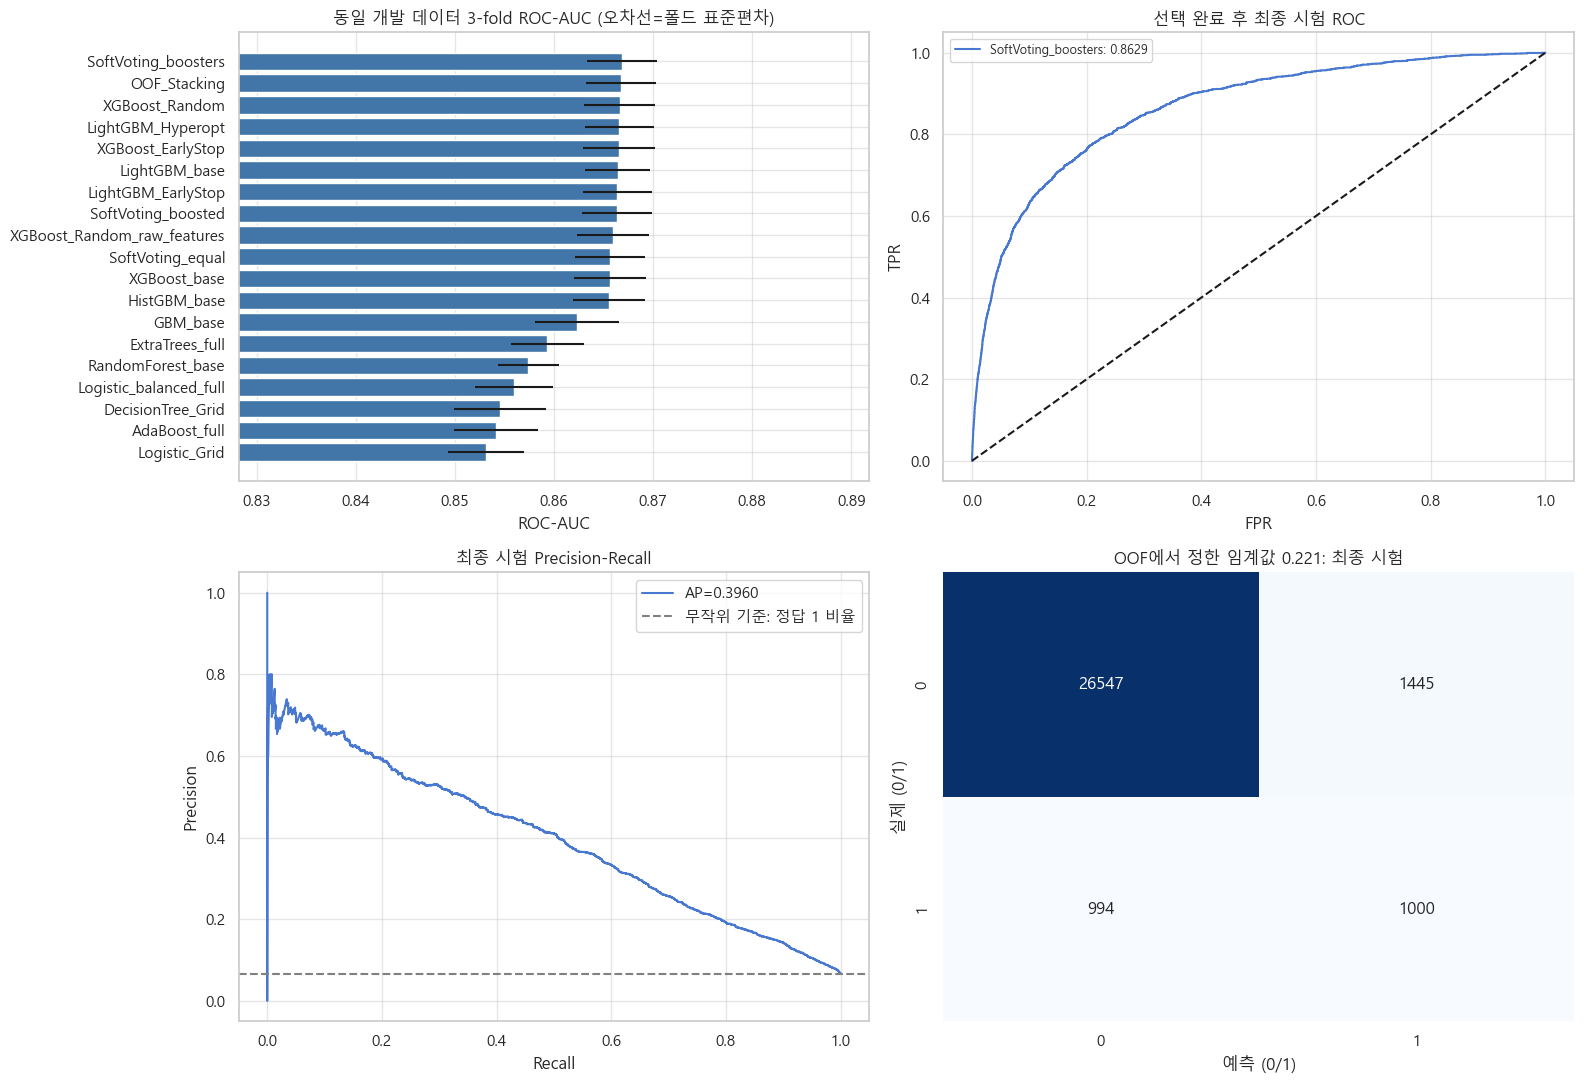

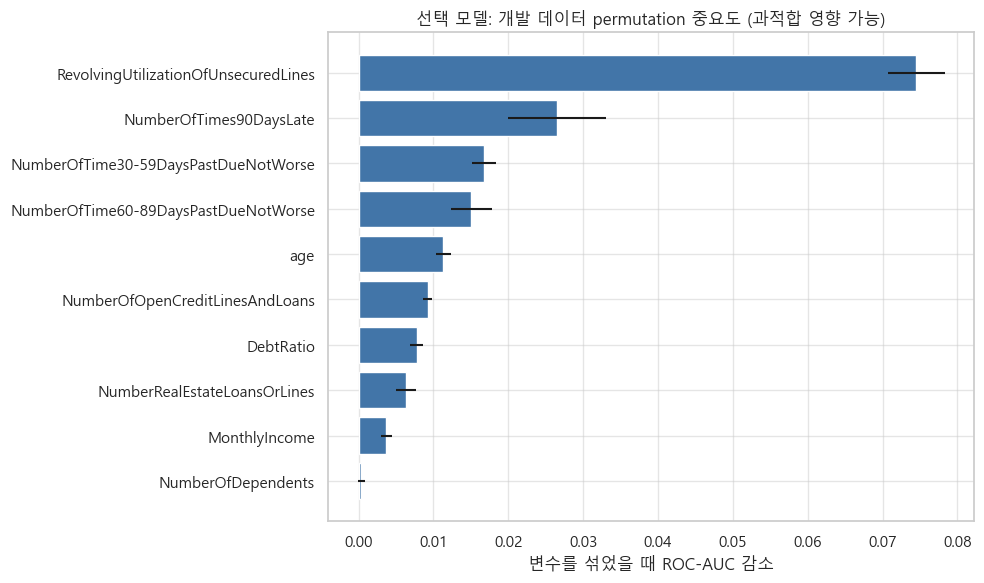

제출 파일 검증 완료: (101503, 2)
1·2위 CV AUC 차이: 8.292922235242361e-05
결과 보고서: C:\Users\KDT76\OneDrive\문서\MachineLearning\프로젝트1조\model_results\분석결과.md


In [12]:
# 모델 선택 완료 후 최종 시험 평가 → 전체 학습 자료 재학습 → 로컬 제출 파일.
# 시험 점수를 본 뒤 후보를 다시 고르지 않습니다.
import json
import importlib.metadata as metadata
holdout_results = experiment.finalize()
display(holdout_results.round(5))
print(experiment.summary)
experiment.plots()
report = experiment.write_report()
ranking = pd.DataFrame(experiment.full_rows).sort_values('ROC_AUC', ascending=False)
gap = float(ranking.iloc[0]['ROC_AUC'] - ranking.iloc[1]['ROC_AUC'])
report += '\n## 개발 CV 상세 비교\n\n' + ranking.to_csv(index=False)
report += f'\n\n1위와 2위의 평균 AUC 차이: {gap:.6f}. 작은 차이는 우연일 수 있으며 한 번의 시험 분할만으로 확실한 우열을 주장하지 않습니다.\n'
report += '\n이전 EDA에는 전체 자료를 사용했습니다. 모델·설정 선정에 시험 점수는 사용하지 않았지만 전체 연구 과정에서 완전히 미열람 상태였던 시험이라고 주장하지 않습니다.\n'
report += '\n조기 종료는 내부 그룹 검증에서 트리 수를 고른 뒤 바깥 학습 자료 전체에 재학습하여 비교했습니다.\n'
(experiment.out / '분석결과.md').write_text(report, encoding='utf-8')
params = experiment.candidates[experiment.winner_name].get_params(deep=True)
(experiment.out / 'selected_model_parameters.json').write_text(json.dumps(params, indent=2, default=str), encoding='utf-8')
config = json.loads((experiment.out / 'experiment_config.json').read_text(encoding='utf-8'))
requirements = [f'{name}=={version}' for name, version in config['versions'].items()]
requirements += [f'xlrd=={metadata.version("xlrd")}', f'joblib=={metadata.version("joblib")}']
(experiment.out / 'model_requirements.txt').write_text('\n'.join(requirements), encoding='utf-8')
# 제출 예시의 ID 순서·행 수와 일치하는지 확인합니다.
prediction_file = pd.read_csv(experiment.out / 'submission_best.csv')
assert prediction_file['Id'].tolist() == submission['Id'].tolist()
assert np.isfinite(prediction_file['Probability']).all()
print('제출 파일 검증 완료:', prediction_file.shape)
print('1·2위 CV AUC 차이:', gap)
print('결과 보고서:', experiment.out / '분석결과.md')


## 최종 추천: XGBoost + LightGBM 소프트 보팅

**이번 실험의 1위는 두 모델의 연체 확률을 50:50으로 평균하는 방법입니다.**

| 개발 데이터 전체 3-fold 순위 | 평균 ROC-AUC |
|---|---:|
| XGBoost + LightGBM 소프트 보팅 | 0.866821 |
| 내부 OOF 스태킹 | 0.866739 |
| 튜닝한 XGBoost 단독 | 0.866616 |
| 튜닝한 LightGBM 단독 | 0.866564 |

19개 최종 후보·변형을 같은 개발 폴드에서 비교했습니다(1차는 12개 모델). 하드 보팅은 별도 지표로 기록했습니다.
1위와 2위 차이는 0.000083으로 매우 작아 통계적으로 확실한 우위라고 단정하지 않습니다.
단순한 단일 모델이 필요하면 XGBoost도 근접한 대안이지만, 제출용 파일은 사전에 정한 기준의 1위로 만들었습니다.

### 별도로 남긴 약 3만 명의 최종 시험 결과

- ROC-AUC **0.862869**, 95% 부트스트랩 구간 **0.854753~0.870477**
- AP(불균형 데이터에서의 PR 요약 지표) **0.396011**
- 기본 임계값 0.5: 정확도 93.77%, 정밀도 59.60%, 재현율 19.46%, F1 0.2934
- 개발 OOF에서 F1으로 선택한 임계값 약 0.221: 정확도 91.87%, 정밀도 40.90%, 재현율 50.15%, F1 0.4506

**정확도를 조금 낮추더라도 연체자를 더 찾아내려면 임계값 조정이 중요합니다.**
0.221은 실제 대출 손실 비용을 최적화한 기준이 아니라 이번 실습의 F1 기준입니다.

### 발표할 때 설명할 선택 이유

> 결측 대체와 스케일링을 검증 폴드 안에서 수행하고, 동일한 데이터 분할에서 여러 모델을 비교했습니다.
> ROC-AUC를 주 지표로 설정했으며, XGBoost와 LightGBM의 확률을 평균한 소프트 보팅이 개발 검증에서 최고였습니다.
> 별도 시험 자료에서도 AUC 0.8629를 확인했습니다. 스태킹과의 점수 차이는 작아서 확실한 우위라고 과장하지 않았습니다.
> 연체 여부가 불균형하므로 정확도만 보지 않고 AP·재현율·F1을 함께 확인했습니다.

### 저장 파일

- `model_results/분석결과.md`: 전체 결론·주의점·상세 비교
- `model_results/full_cv_results.csv`: 최종 후보 비교표
- `model_results/submission_best.csv`: 101,503명 예측 확률. 외부 제출은 하지 않음.
- `model_results/submission_model.joblib`: 전체 15만 명으로 재학습한 제출용 모델
- `credit_experiment.py`: 전처리·모든 모델·탐색·보팅·스태킹의 구현과 주석
- `credit_early_stop.py`: 내부 그룹 검증 조기 종료 구현

검증용 모델과 전체 데이터 재학습 모델은 다릅니다. 위 시험 점수는 `holdout_model.joblib`의 성능이며, 전체 재학습 모델의 정답 없는 cs-test 성능은 알 수 없습니다.
보팅의 Seconds=0은 저장된 OOF 예측을 재사용한 추가 계산 시간 표기이며 학습 비용이 0이라는 의미가 아닙니다.
모델을 불러올 때 두 Python 모듈과 기록된 패키지 버전이 필요합니다.


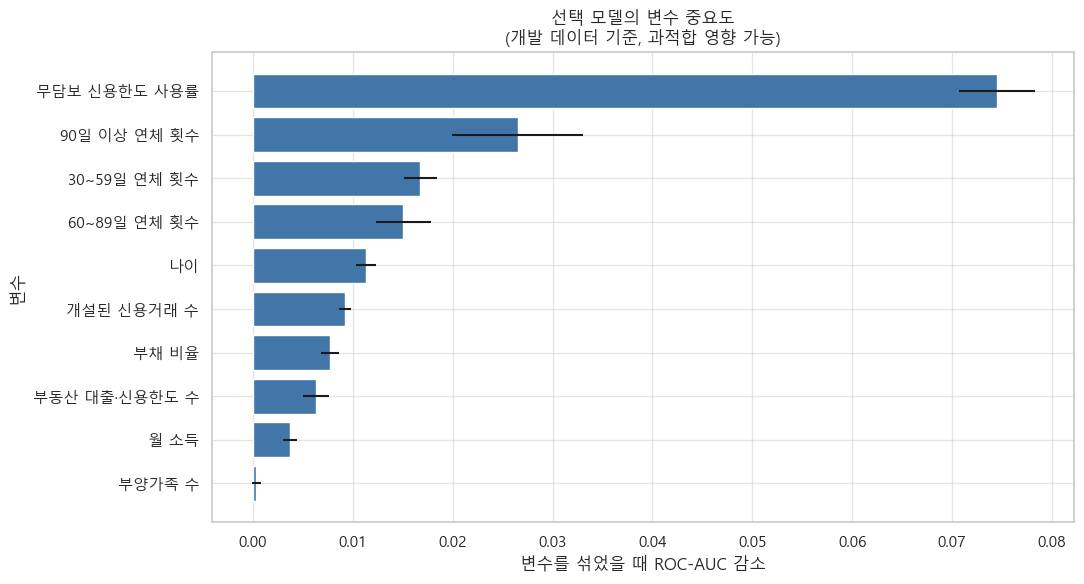

In [15]:
# 저장된 중요도 결과를 한글로 표시합니다. 모델을 다시 학습하지 않습니다.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

result_dir = next(p for p in [Path.cwd() / 'model_results', Path.cwd() / '프로젝트1조' / 'model_results']
                  if (p / 'permutation_importance_development.csv').exists())
korean_names = {
    'RevolvingUtilizationOfUnsecuredLines': '무담보 신용한도 사용률',
    'NumberOfTimes90DaysLate': '90일 이상 연체 횟수',
    'NumberOfTime30-59DaysPastDueNotWorse': '30~59일 연체 횟수',
    'NumberOfTime60-89DaysPastDueNotWorse': '60~89일 연체 횟수',
    'age': '나이',
    'NumberOfOpenCreditLinesAndLoans': '개설된 신용거래 수',
    'DebtRatio': '부채 비율',
    'NumberRealEstateLoansOrLines': '부동산 대출·신용한도 수',
    'MonthlyIncome': '월 소득',
    'NumberOfDependents': '부양가족 수'
}
importance_ko = pd.read_csv(result_dir / 'permutation_importance_development.csv').sort_values('importance')
importance_ko['변수'] = importance_ko['feature'].map(korean_names)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(importance_ko['변수'], importance_ko['importance'],
        xerr=importance_ko['std'], color='#4275a8')
ax.set_title('선택 모델의 변수 중요도\n(개발 데이터 기준, 과적합 영향 가능)')
ax.set_xlabel('변수를 섞었을 때 ROC-AUC 감소')
ax.set_ylabel('변수')
fig.tight_layout()
fig.savefig(result_dir / 'feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)


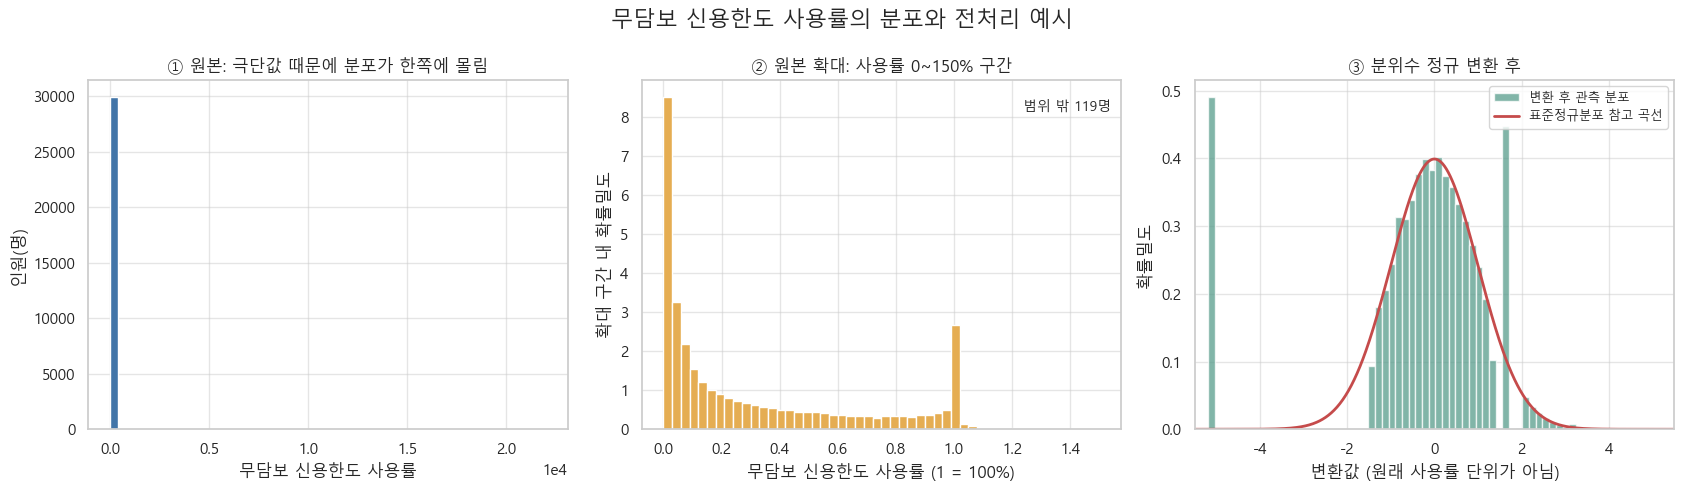

원본 전체 개수: 150000 / 변환 기준 학습: 120000 / 표시용 검증: 30000
변환 후 -5 부근의 봉우리는 0 등 같은 값이 많아 생깁니다. 완벽한 정규분포가 된 것은 아닙니다.
주의: StandardScaler는 평균·표준편차만 바꾸므로 원래 분포를 정규분포로 만들지 않습니다.
이 그림은 별도 전처리 예시입니다. 기존 최종 모델과 제출 파일에는 적용하지 않았습니다.


In [16]:
# 무담보 신용한도 사용률: 전처리 전후 분포 비교 (시각화용)
# 정규분포처럼 만드는 것이 모든 모델에 필요한 것은 아닙니다.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import QuantileTransformer
from sklearn.model_selection import train_test_split
from scipy.stats import norm

data_dir = next(p for p in [Path.cwd(), Path.cwd() / '프로젝트1조'] if (p / 'cs-training.csv').exists())
utilization = pd.read_csv(data_dir / 'cs-training.csv', usecols=['RevolvingUtilizationOfUnsecuredLines']).iloc[:, 0].dropna()
# 변환 기준은 학습용 부분에서만 계산합니다. 모델 비교 실험에는 영향을 주지 않는 별도 시각화입니다.
util_fit, util_view = train_test_split(utilization.to_numpy().reshape(-1, 1), test_size=.2, random_state=42)
normal_transformer = QuantileTransformer(n_quantiles=1000, output_distribution='normal',
                                        subsample=len(util_fit), random_state=42)
normal_transformer.fit(util_fit)
normal_view = normal_transformer.transform(util_view).ravel()
original_view = util_view.ravel()

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].hist(original_view, bins=60, color='#4275a8', edgecolor='white')
axes[0].set(title='① 원본: 극단값 때문에 분포가 한쪽에 몰림', xlabel='무담보 신용한도 사용률', ylabel='인원(명)')
axes[0].ticklabel_format(axis='x', style='sci', scilimits=(0, 0))

# 0~1.5 범위로 확대만 하며, 원본 값을 삭제하거나 수정하지 않습니다.
zoom = original_view[(original_view >= 0) & (original_view <= 1.5)]
axes[1].hist(zoom, bins=50, density=True, color='#e5ad52', edgecolor='white')
axes[1].set(title='② 원본 확대: 사용률 0~150% 구간', xlabel='무담보 신용한도 사용률 (1 = 100%)', ylabel='확대 구간 내 확률밀도')
axes[1].text(.98, .94, f'범위 밖 {len(original_view)-len(zoom):,}명', transform=axes[1].transAxes,
             ha='right', va='top', fontsize=10)

axes[2].hist(normal_view, bins=55, density=True, color='#579c8b', alpha=.75, edgecolor='white', label='변환 후 관측 분포')
grid = np.linspace(-5.5, 5.5, 500)
axes[2].plot(grid, norm.pdf(grid), color='#c54b4b', linewidth=2, label='표준정규분포 참고 곡선')
axes[2].set(title='③ 분위수 정규 변환 후', xlabel='변환값 (원래 사용률 단위가 아님)', ylabel='확률밀도', xlim=(-5.5, 5.5))
axes[2].legend(fontsize=9)
fig.suptitle('무담보 신용한도 사용률의 분포와 전처리 예시', fontsize=16)
fig.tight_layout()
output_path = data_dir / 'graphs' / '04_신용한도사용률_정규변환.png'
output_path.parent.mkdir(exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
print('원본 전체 개수:', len(utilization), '/ 변환 기준 학습:', len(util_fit), '/ 표시용 검증:', len(util_view))
print('변환 후 -5 부근의 봉우리는 0 등 같은 값이 많아 생깁니다. 완벽한 정규분포가 된 것은 아닙니다.')
print('주의: StandardScaler는 평균·표준편차만 바꾸므로 원래 분포를 정규분포로 만들지 않습니다.')
print('이 그림은 별도 전처리 예시입니다. 기존 최종 모델과 제출 파일에는 적용하지 않았습니다.')


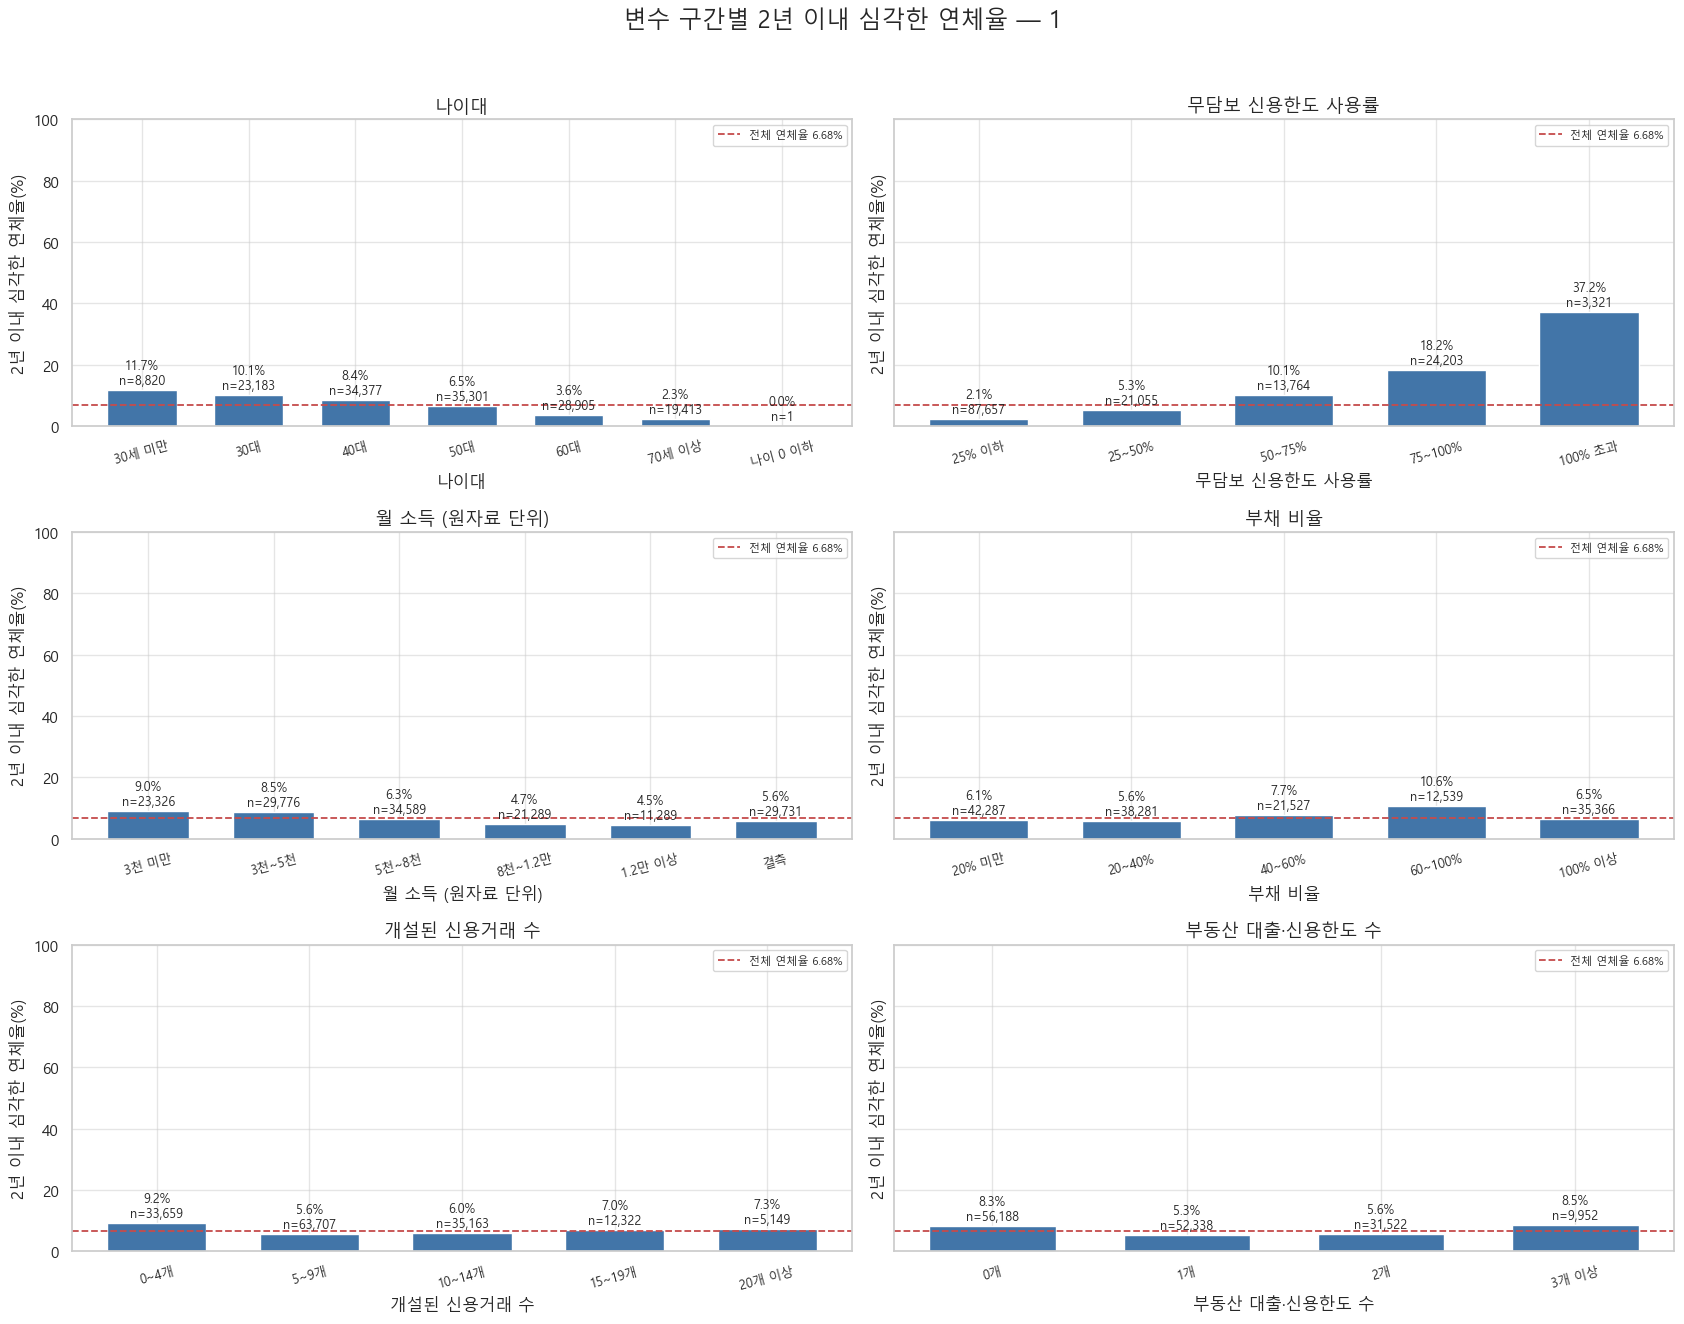

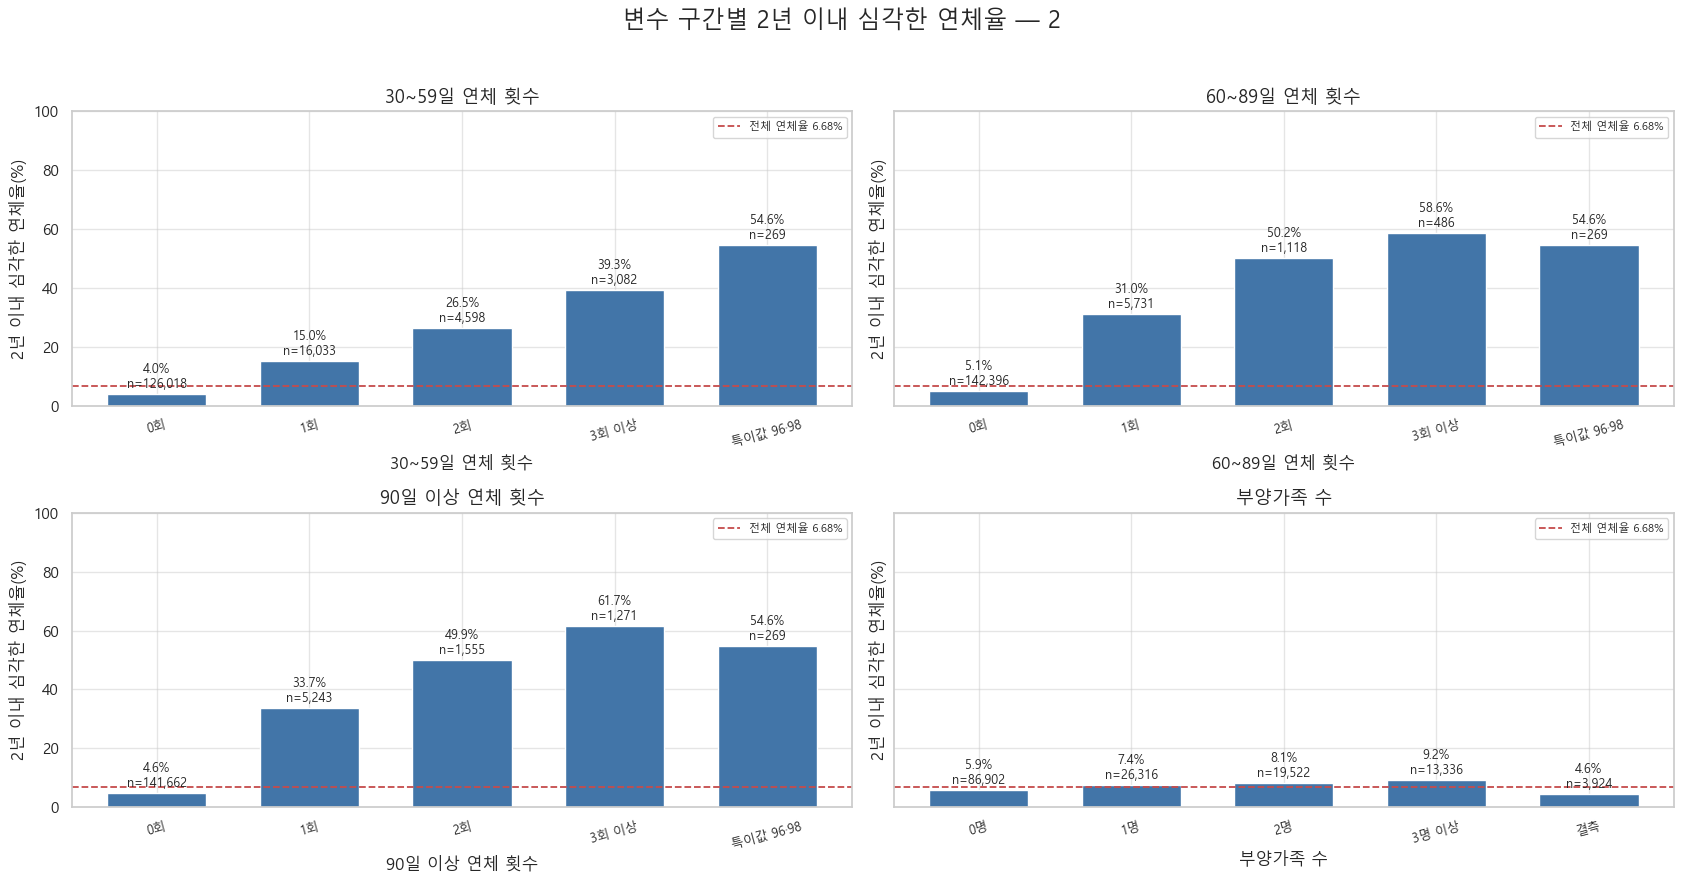

연체율 = 해당 구간의 정답 1 인원 ÷ 해당 구간 전체 인원 × 100
전체 150,000명의 탐색용 집계입니다. 모든 그래프의 세로축은 0~100%입니다.
n은 구간 인원수입니다. 특히 나이 0 이하 구간은 1명이므로 일반화할 수 없습니다.
구간은 왼쪽 경계 포함·오른쪽 제외이며, 신용한도 사용률만 오른쪽 경계 포함입니다.
월소득은 원자료 단위를 사용하며 원화로 해석하지 않습니다. 관찰된 관계는 인과관계가 아닙니다.


In [17]:
# 각 변수 구간별 '2년 이내 심각한 연체율' 비교
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

credit_dir = next(p for p in [Path.cwd(), Path.cwd() / '프로젝트1조'] if (p / 'cs-training.csv').exists())
rate_df = pd.read_csv(credit_dir / 'cs-training.csv', index_col=0)
rate_target = 'SeriousDlqin2yrs'
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def interval_groups(series, bins, labels):
    return pd.cut(series, bins=bins, labels=labels, right=False).astype(object).fillna('결측')

def count_groups(series):
    # 96/98은 실제 횟수로 단정하지 않고 별도 구간으로 보존합니다.
    return series.map(lambda v: '결측' if pd.isna(v) else
                      '특이값 96·98' if v in [96, 98] else
                      str(int(v))+'회' if v < 3 else '3회 이상')

age = rate_df['age']
age_group = interval_groups(age, [0,30,40,50,60,70,np.inf],
                            ['30세 미만','30대','40대','50대','60대','70세 이상'])
age_group.loc[age <= 0] = '나이 0 이하'
util_group = pd.cut(rate_df['RevolvingUtilizationOfUnsecuredLines'],
                    [-np.inf,.25,.5,.75,1,np.inf], right=True,
                    labels=['25% 이하','25~50%','50~75%','75~100%','100% 초과']).astype(object).fillna('결측')
income_group = interval_groups(rate_df['MonthlyIncome'],
    [0,3000,5000,8000,12000,np.inf], ['3천 미만','3천~5천','5천~8천','8천~1.2만','1.2만 이상'])
debt_group = interval_groups(rate_df['DebtRatio'],
    [0,.2,.4,.6,1,np.inf], ['20% 미만','20~40%','40~60%','60~100%','100% 이상'])
open_group = interval_groups(rate_df['NumberOfOpenCreditLinesAndLoans'],
    [0,5,10,15,20,np.inf], ['0~4개','5~9개','10~14개','15~19개','20개 이상'])
estate_group = rate_df['NumberRealEstateLoansOrLines'].map(lambda v: str(int(v))+'개' if v<3 else '3개 이상')
dependent_group = rate_df['NumberOfDependents'].map(
    lambda v: '결측' if pd.isna(v) else str(int(v))+'명' if v<3 else '3명 이상')

rate_specs = [
    ('나이대', age_group, ['30세 미만','30대','40대','50대','60대','70세 이상','나이 0 이하']),
    ('무담보 신용한도 사용률', util_group, ['25% 이하','25~50%','50~75%','75~100%','100% 초과']),
    ('월 소득 (원자료 단위)', income_group, ['3천 미만','3천~5천','5천~8천','8천~1.2만','1.2만 이상','결측']),
    ('부채 비율', debt_group, ['20% 미만','20~40%','40~60%','60~100%','100% 이상']),
    ('개설된 신용거래 수', open_group, ['0~4개','5~9개','10~14개','15~19개','20개 이상']),
    ('부동산 대출·신용한도 수', estate_group, ['0개','1개','2개','3개 이상']),
    ('30~59일 연체 횟수', count_groups(rate_df['NumberOfTime30-59DaysPastDueNotWorse']),
        ['0회','1회','2회','3회 이상','특이값 96·98']),
    ('60~89일 연체 횟수', count_groups(rate_df['NumberOfTime60-89DaysPastDueNotWorse']),
        ['0회','1회','2회','3회 이상','특이값 96·98']),
    ('90일 이상 연체 횟수', count_groups(rate_df['NumberOfTimes90DaysLate']),
        ['0회','1회','2회','3회 이상','특이값 96·98']),
    ('부양가족 수', dependent_group, ['0명','1명','2명','3명 이상','결측'])
]
rate_tables = []
baseline_rate = rate_df[rate_target].mean()*100
rate_output = credit_dir / 'graphs'
rate_output.mkdir(exist_ok=True)

for page, subset in enumerate([rate_specs[:6], rate_specs[6:]], start=1):
    rows = 3 if page == 1 else 2
    fig, axes = plt.subplots(rows, 2, figsize=(17, rows*4.5), sharey=True)
    for ax, (name, groups, order) in zip(axes.flat, subset):
        stats = rate_df.groupby(groups, observed=True)[rate_target].agg(['mean','size','sum']).reindex(order).dropna()
        rates = stats['mean']*100
        bars = ax.bar(stats.index.astype(str), rates, color='#4275a8', width=.65)
        ax.axhline(baseline_rate, color='#c54b4b', linestyle='--', linewidth=1.3,
                   label=f'전체 연체율 {baseline_rate:.2f}%')
        for bar, (group, row) in zip(bars, stats.iterrows()):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
                    f'{row["mean"]*100:.1f}%\nn={int(row["size"]):,}',
                    ha='center', va='bottom', fontsize=9)
        ax.set_title(name, fontsize=13)
        ax.set_xlabel(name)
        ax.set_ylabel('2년 이내 심각한 연체율(%)')
        ax.set_ylim(0, 100)
        ax.tick_params(axis='x', labelrotation=15, labelsize=9)
        ax.legend(loc='upper right', fontsize=8)
        tidy = stats.rename(columns={'size':'인원','sum':'연체 인원','mean':'연체 비율'}).reset_index()
        tidy.columns = ['구간','연체 비율','인원','연체 인원']
        tidy.insert(0, '변수', name)
        tidy['연체율(%)'] = tidy['연체 비율']*100
        rate_tables.append(tidy)
    fig.suptitle('변수 구간별 2년 이내 심각한 연체율 — '+str(page), fontsize=17)
    fig.tight_layout(rect=[0,0,1,.96])
    fig.savefig(rate_output / f'05_변수별연체율_{page}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

pd.concat(rate_tables, ignore_index=True).to_csv(rate_output / '05_변수별연체율_집계.csv', index=False, encoding='utf-8-sig')
print('연체율 = 해당 구간의 정답 1 인원 ÷ 해당 구간 전체 인원 × 100')
print('전체 150,000명의 탐색용 집계입니다. 모든 그래프의 세로축은 0~100%입니다.')
print('n은 구간 인원수입니다. 특히 나이 0 이하 구간은 1명이므로 일반화할 수 없습니다.')
print('구간은 왼쪽 경계 포함·오른쪽 제외이며, 신용한도 사용률만 오른쪽 경계 포함입니다.')
print('월소득은 원자료 단위를 사용하며 원화로 해석하지 않습니다. 관찰된 관계는 인과관계가 아닙니다.')


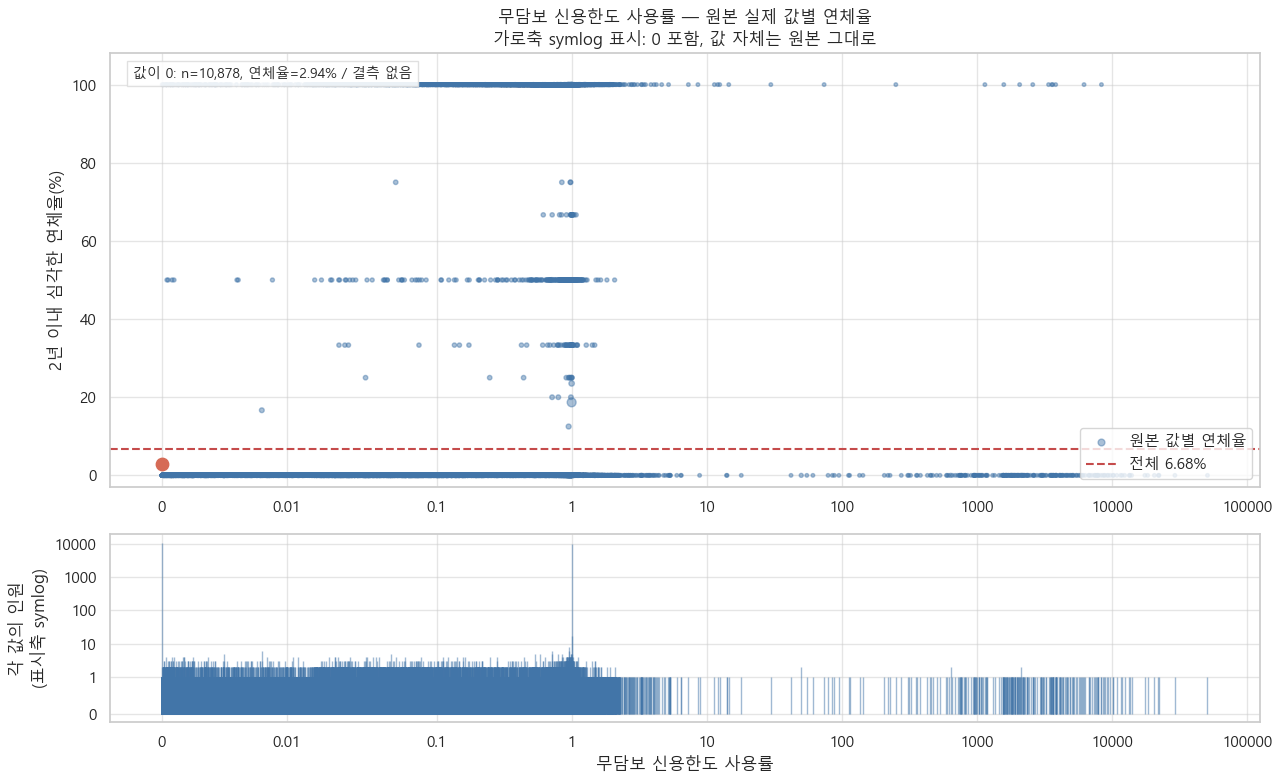

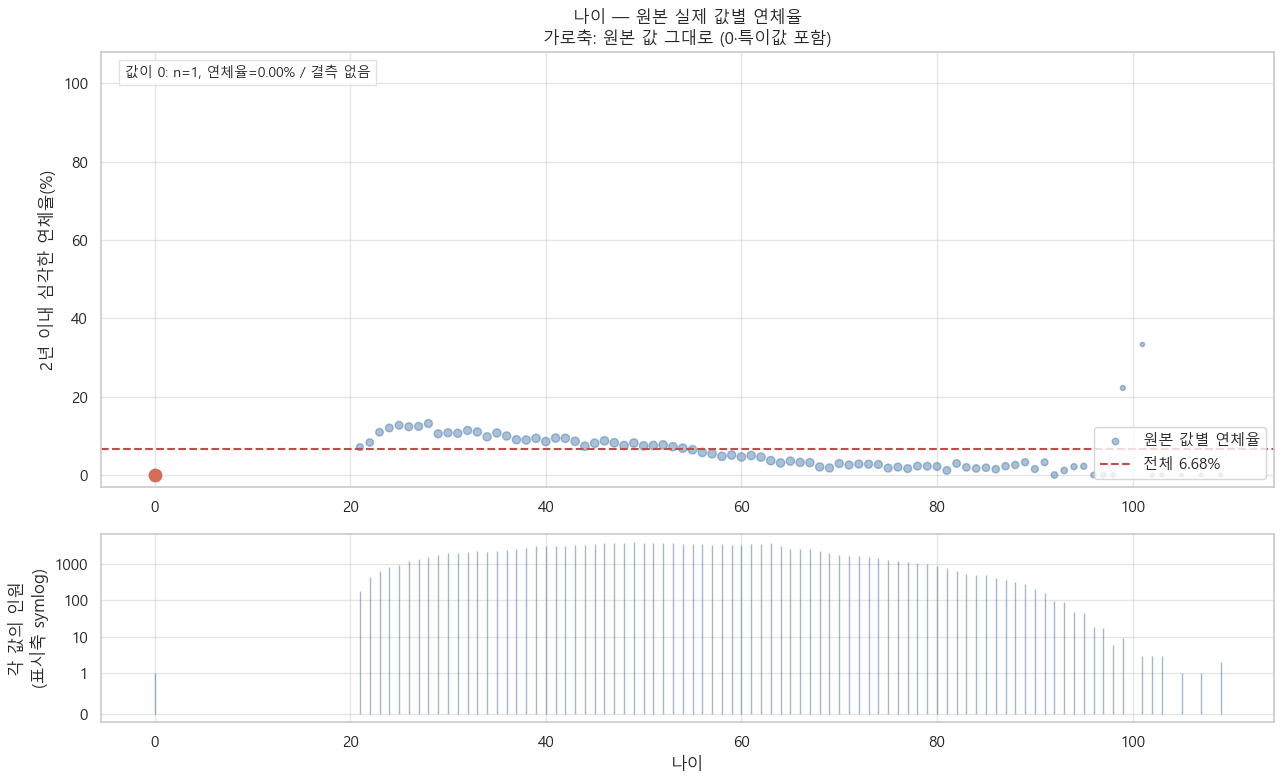

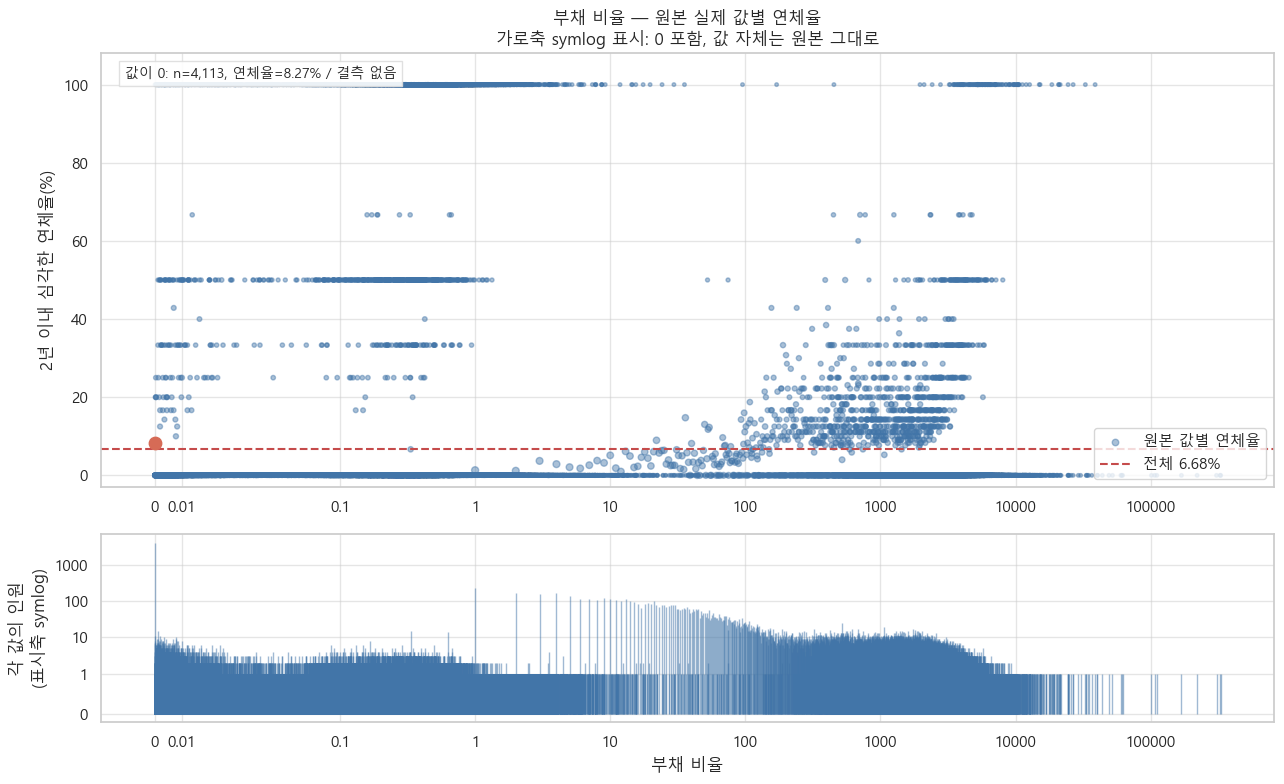

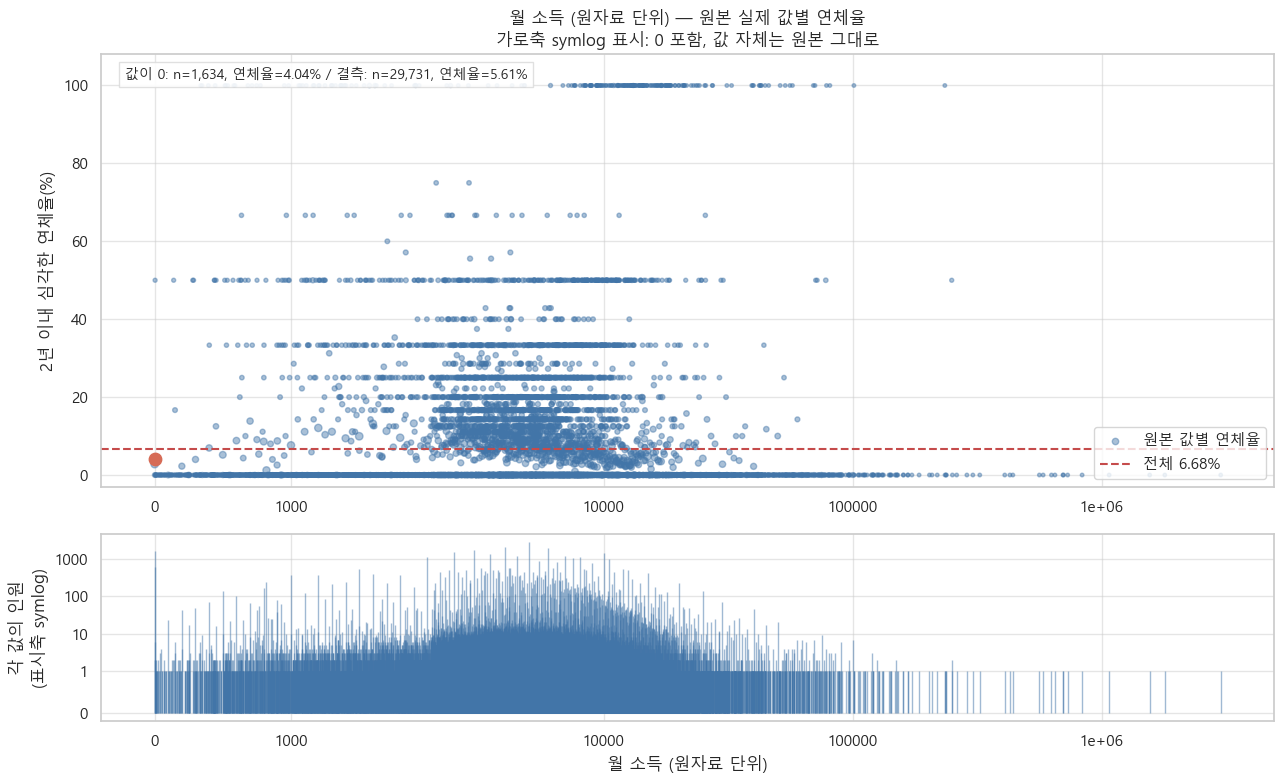

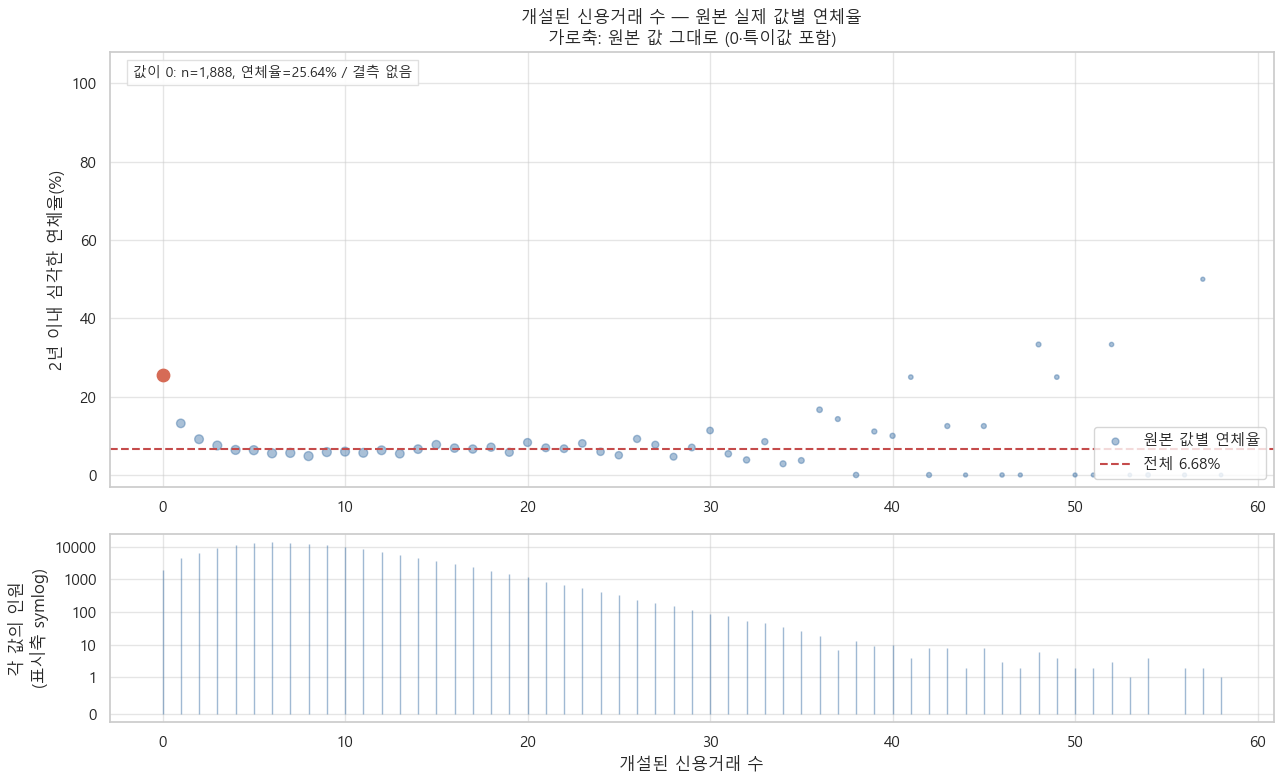

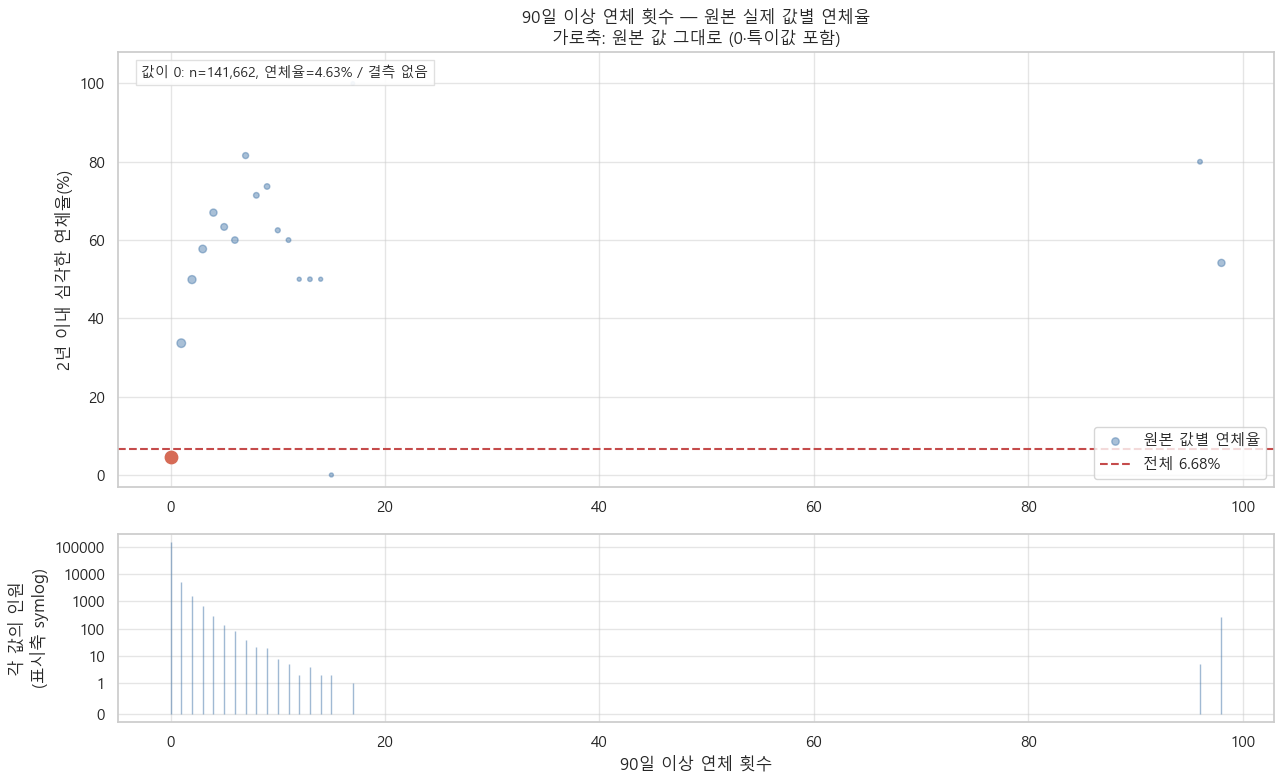

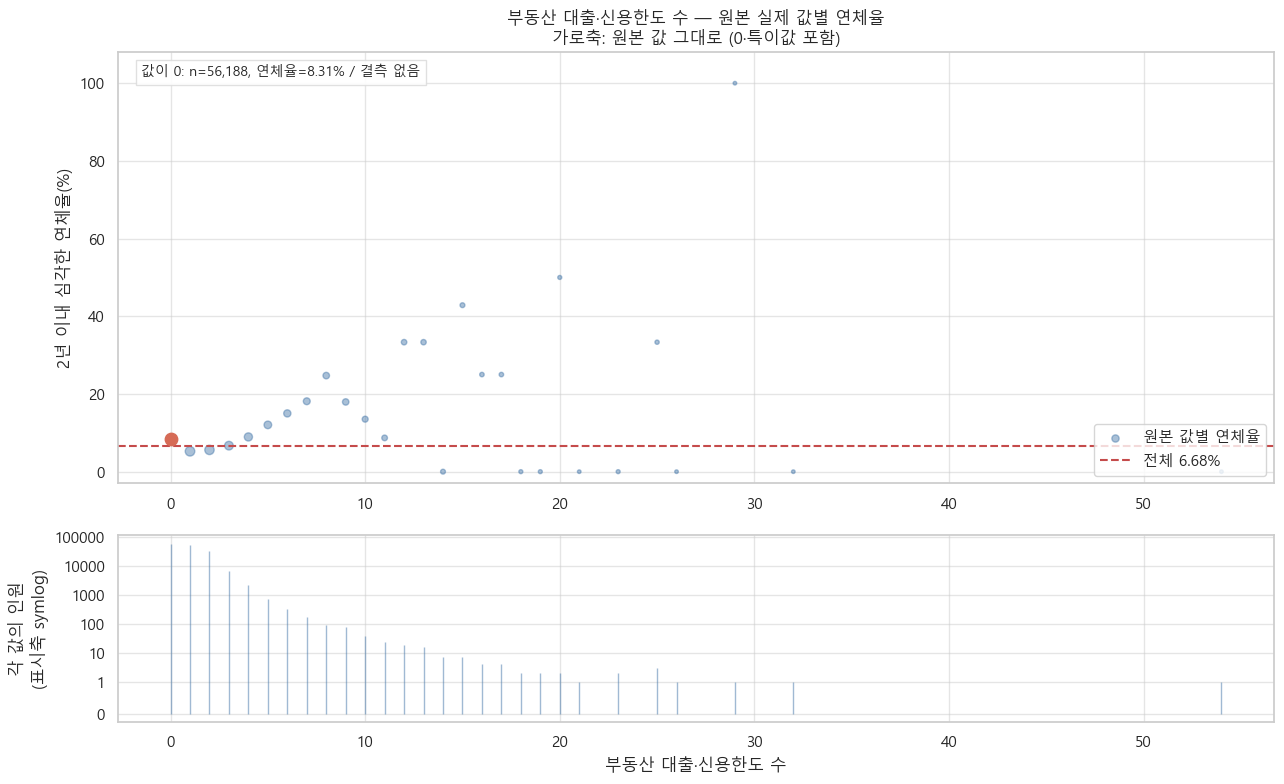

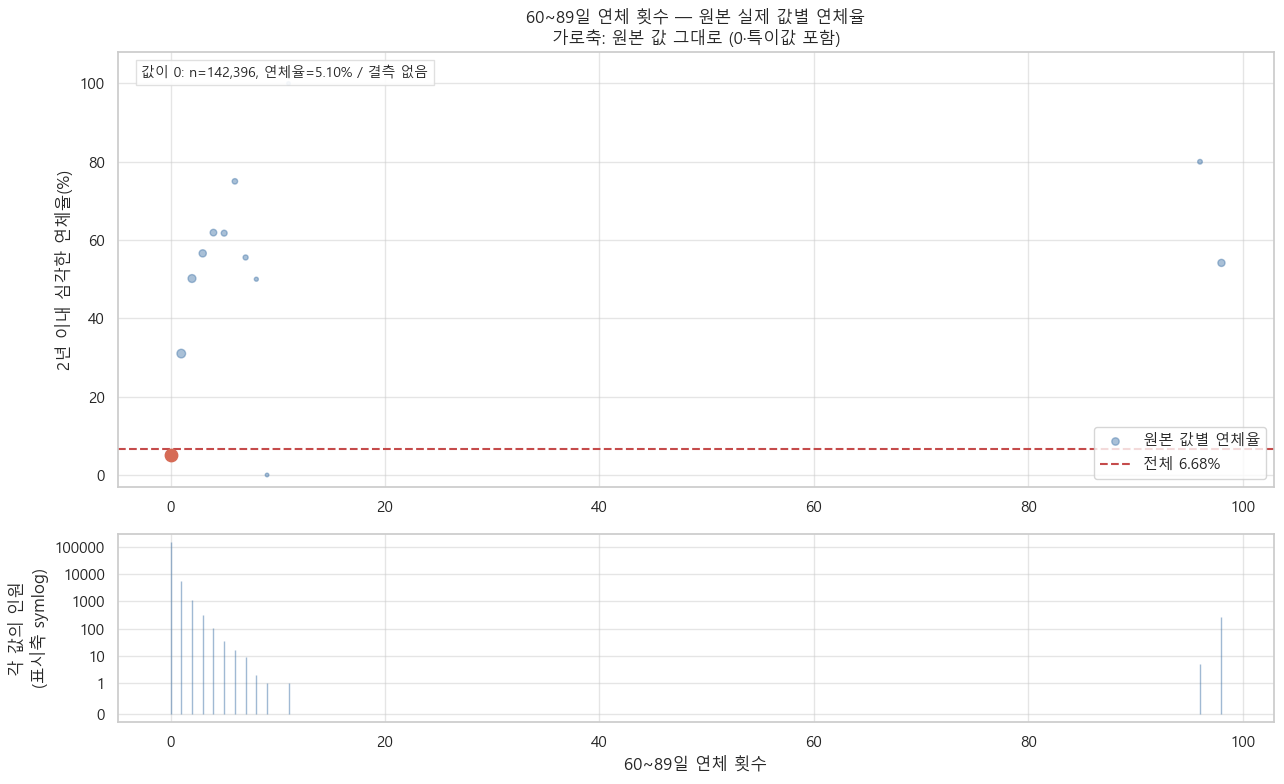

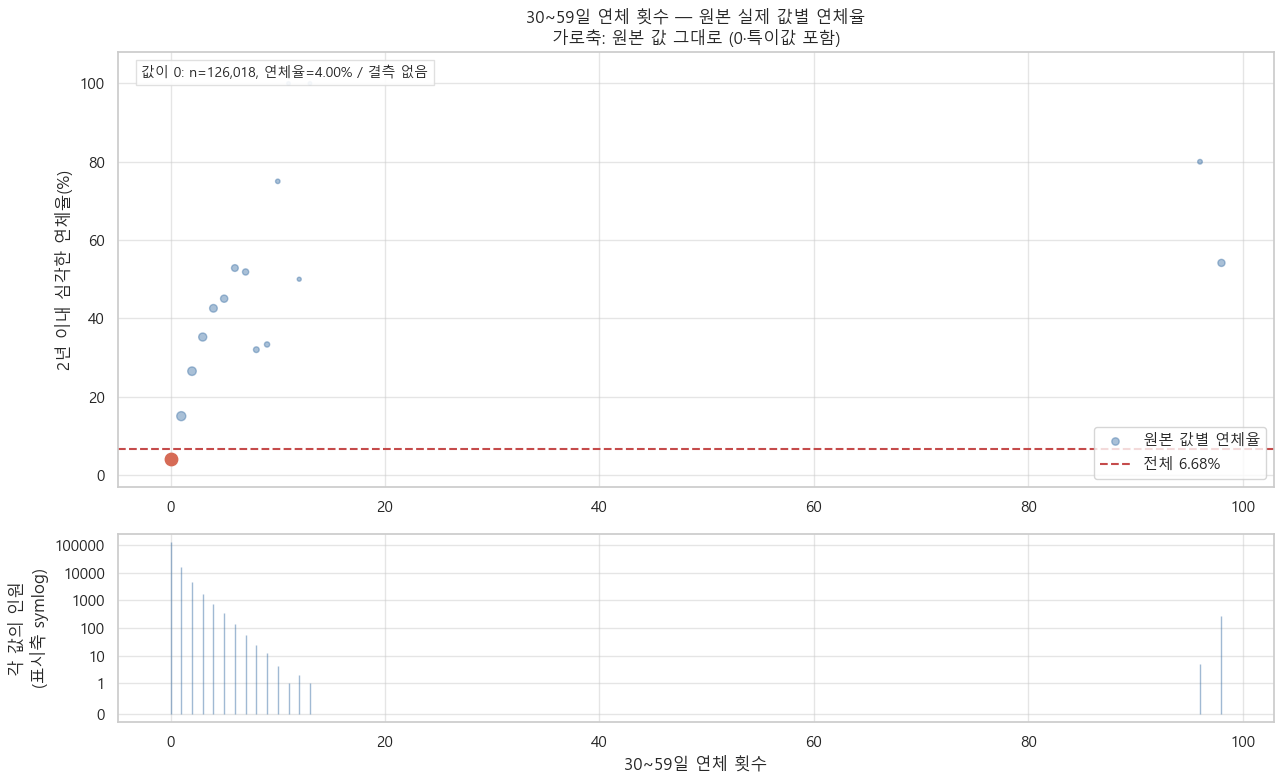

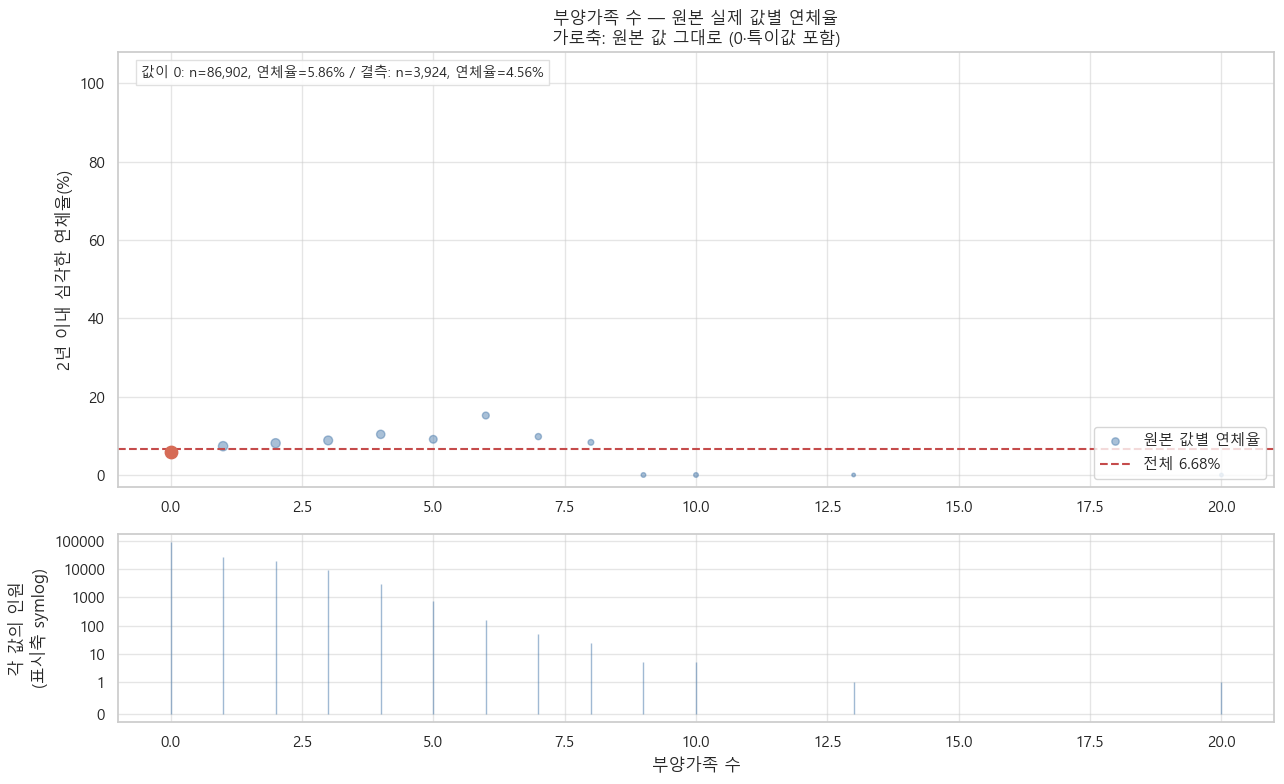

CSV에서 다시 읽은 원본 150,000명 전체. 0·96·98·결측을 삭제하거나 대체하지 않았습니다.
연속형 변수는 원본 값이 같은 사람끼리만 집계했습니다. 1명뿐인 값은 연체율이 0% 또는 100%일 수 있습니다.
symlog는 표시축만 압축하며 원본 데이터를 가공하거나 정규화하지 않습니다.


In [19]:
# 원본 CSV 그대로: 대체·로그 변환·구간 통합 없이 각 실제 값별 연체율
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

raw_dir = next(p for p in [Path.cwd(), Path.cwd() / '프로젝트1조'] if (p / 'cs-training.csv').exists())
raw_credit = pd.read_csv(raw_dir / 'cs-training.csv', index_col=0)
raw_target = 'SeriousDlqin2yrs'
raw_names = {
    'RevolvingUtilizationOfUnsecuredLines': '무담보 신용한도 사용률',
    'age': '나이', 'DebtRatio': '부채 비율', 'MonthlyIncome': '월 소득 (원자료 단위)',
    'NumberOfOpenCreditLinesAndLoans': '개설된 신용거래 수',
    'NumberOfTimes90DaysLate': '90일 이상 연체 횟수',
    'NumberRealEstateLoansOrLines': '부동산 대출·신용한도 수',
    'NumberOfTime60-89DaysPastDueNotWorse': '60~89일 연체 횟수',
    'NumberOfTime30-59DaysPastDueNotWorse': '30~59일 연체 횟수',
    'NumberOfDependents': '부양가족 수'
}
raw_output = raw_dir / 'graphs' / 'raw'
raw_output.mkdir(parents=True, exist_ok=True)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
raw_baseline = raw_credit[raw_target].mean()*100
raw_aggregates = []
raw_image_paths = []

for number, (column, name) in enumerate(raw_names.items(), 1):
    grouped = raw_credit.groupby(column, dropna=False)[raw_target].agg(['mean','size','sum']).sort_index()
    nonmissing = grouped.loc[grouped.index.notna()]
    fig, (ax, count_ax) = plt.subplots(2, 1, figsize=(13, 8), gridspec_kw={'height_ratios':[3,1.3]})
    # 연속형도 반올림 없이 실제 값별로 집계. 표본이 적은 값은 연체율이 0/100%가 되기 쉽습니다.
    scatter = ax.scatter(nonmissing.index, nonmissing['mean']*100,
                         s=np.clip(4 + np.log1p(nonmissing['size'])*4, 5, 50),
                         alpha=.45, color='#4275a8', label='원본 값별 연체율')
    ax.axhline(raw_baseline, color='#c54b4b', linestyle='--', label=f'전체 {raw_baseline:.2f}%')
    count_ax.vlines(nonmissing.index, 0, nonmissing['size'], color='#4275a8', alpha=.5, linewidth=1)
    # 값은 변환하지 않고 표시축만 압축해 0과 큰 극단값을 함께 표시합니다.
    continuous = nonmissing.shape[0] > 120
    if continuous:
        positive = nonmissing.index.to_numpy(dtype=float)
        positive = positive[positive > 0]
        linthresh = float(np.quantile(positive, .1)) if len(positive) else 1.
        linthresh = max(linthresh, .001)
        ax.set_xscale('symlog', linthresh=linthresh)
        count_ax.set_xscale('symlog', linthresh=linthresh)
        for axis in [ax, count_ax]:
            axis.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f'{v:g}'))
    zero_text = '0인 기록 없음'
    if 0 in nonmissing.index:
        row = nonmissing.loc[0]
        ax.scatter([0], [row['mean']*100], color='#d66b56', s=80, zorder=5)
        zero_text = f'값이 0: n={int(row["size"]):,}, 연체율={row["mean"]*100:.2f}%'
    missing_text = '결측 없음'
    if grouped.index.isna().any():
        row = grouped.loc[grouped.index.isna()].iloc[0]
        missing_text = f'결측: n={int(row["size"]):,}, 연체율={row["mean"]*100:.2f}%'
    ax.text(.02,.97, zero_text+' / '+missing_text, transform=ax.transAxes, va='top',
            bbox={'facecolor':'white','alpha':.9,'edgecolor':'#dddddd'}, fontsize=10)
    ax.set_ylim(-3,108)
    ax.set_ylabel('2년 이내 심각한 연체율(%)')
    ax.legend(loc='lower right')
    count_ax.set_yscale('symlog', linthresh=1)
    count_ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f'{v:g}'))
    count_ax.set_ylabel('각 값의 인원\n(표시축 symlog)')
    scale_note = '가로축 symlog 표시: 0 포함, 값 자체는 원본 그대로' if continuous else '가로축: 원본 값 그대로 (0·특이값 포함)'
    ax.set_title(name+' — 원본 실제 값별 연체율\n'+scale_note)
    count_ax.set_xlabel(name)
    fig.tight_layout()
    path = raw_output / f'{number:02d}_원본값별연체율.png'
    fig.savefig(path, dpi=140, bbox_inches='tight')
    raw_image_paths.append(path)
    plt.show()
    plt.close(fig)
    table = grouped.reset_index()
    table.columns = ['원본 값','연체 비율','인원','연체 인원']
    table.insert(0,'변수',column)
    table['연체율(%)'] = table['연체 비율']*100
    raw_aggregates.append(table)

pd.concat(raw_aggregates, ignore_index=True).to_csv(raw_output / '원본값별연체율_집계.csv', index=False, encoding='utf-8-sig')
print('CSV에서 다시 읽은 원본 150,000명 전체. 0·96·98·결측을 삭제하거나 대체하지 않았습니다.')
print('연속형 변수는 원본 값이 같은 사람끼리만 집계했습니다. 1명뿐인 값은 연체율이 0% 또는 100%일 수 있습니다.')
print('symlog는 표시축만 압축하며 원본 데이터를 가공하거나 정규화하지 않습니다.')


In [ ]:
# 각 변수 구간별 '2년 이내 심각한 연체율' 비교
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

credit_dir = next(p for p in [Path.cwd(), Path.cwd() / '프로젝트1조'] if (p / 'cs-training.csv').exists())
rate_df = pd.read_csv(credit_dir / 'cs-training.csv', index_col=0)
rate_target = 'SeriousDlqin2yrs'
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def interval_groups(series, bins, labels):
    return pd.cut(series, bins=bins, labels=labels, right=False).astype(object).fillna('결측')

def count_groups(series):
    # 96/98은 실제 횟수로 단정하지 않고 별도 구간으로 보존합니다.
    return series.map(lambda v: '결측' if pd.isna(v) else
                      '특이값 96·98' if v in [96, 98] else
                      str(int(v))+'회' if v < 3 else '3회 이상')

age = rate_df['age']
age_group = interval_groups(age, [0,30,40,50,60,70,np.inf],
                            ['30세 미만','30대','40대','50대','60대','70세 이상'])
age_group.loc[age <= 0] = '나이 0 이하'
util_group = pd.cut(rate_df['RevolvingUtilizationOfUnsecuredLines'],
                    [-np.inf,.25,.5,.75,1,np.inf], right=True,
                    labels=['25% 이하','25~50%','50~75%','75~100%','100% 초과']).astype(object).fillna('결측')
income_group = interval_groups(rate_df['MonthlyIncome'],
    [0,3000,5000,8000,12000,np.inf], ['3천 미만','3천~5천','5천~8천','8천~1.2만','1.2만 이상'])
debt_group = interval_groups(rate_df['DebtRatio'],
    [0,.2,.4,.6,1,np.inf], ['20% 미만','20~40%','40~60%','60~100%','100% 이상'])
open_group = interval_groups(rate_df['NumberOfOpenCreditLinesAndLoans'],
    [0,5,10,15,20,np.inf], ['0~4개','5~9개','10~14개','15~19개','20개 이상'])
estate_group = rate_df['NumberRealEstateLoansOrLines'].map(lambda v: str(int(v))+'개' if v<3 else '3개 이상')
dependent_group = rate_df['NumberOfDependents'].map(
    lambda v: '결측' if pd.isna(v) else str(int(v))+'명' if v<3 else '3명 이상')

rate_specs = [
    ('나이대', age_group, ['30세 미만','30대','40대','50대','60대','70세 이상','나이 0 이하']),
    ('무담보 신용한도 사용률', util_group, ['25% 이하','25~50%','50~75%','75~100%','100% 초과']),
    ('월 소득 (원자료 단위)', income_group, ['3천 미만','3천~5천','5천~8천','8천~1.2만','1.2만 이상','결측']),
    ('부채 비율', debt_group, ['20% 미만','20~40%','40~60%','60~100%','100% 이상']),
    ('개설된 신용거래 수', open_group, ['0~4개','5~9개','10~14개','15~19개','20개 이상']),
    ('부동산 대출·신용한도 수', estate_group, ['0개','1개','2개','3개 이상']),
    ('30~59일 연체 횟수', count_groups(rate_df['NumberOfTime30-59DaysPastDueNotWorse']),
        ['0회','1회','2회','3회 이상','특이값 96·98']),
    ('60~89일 연체 횟수', count_groups(rate_df['NumberOfTime60-89DaysPastDueNotWorse']),
        ['0회','1회','2회','3회 이상','특이값 96·98']),
    ('90일 이상 연체 횟수', count_groups(rate_df['NumberOfTimes90DaysLate']),
        ['0회','1회','2회','3회 이상','특이값 96·98']),
    ('부양가족 수', dependent_group, ['0명','1명','2명','3명 이상','결측'])
]
# 원본 0은 독립 막대로, 96과 98도 각각 별도 막대로 표시합니다.
# 구간 묶기는 그래프 집계용이며 원본 값 대체나 표본 삭제가 아닙니다.
source_columns = [
    'age', 'RevolvingUtilizationOfUnsecuredLines', 'MonthlyIncome', 'DebtRatio',
    'NumberOfOpenCreditLinesAndLoans', 'NumberRealEstateLoansOrLines',
    'NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate', 'NumberOfDependents'
]
updated_specs = []
for (name, groups, order), column in zip(rate_specs, source_columns):
    groups = groups.copy()
    original = rate_df[column]
    groups.loc[original.eq(0)] = '0'
    order = ['0'] + [label for label in order if label not in ['0회', '0개', '0명', '나이 0 이하', '특이값 96·98']]
    if column == 'age':
        groups = groups.replace({'30세 미만':'1~29세'})
        order = ['1~29세' if label == '30세 미만' else label for label in order]
    elif column == 'RevolvingUtilizationOfUnsecuredLines':
        groups = groups.replace({'25% 이하':'0 초과~25%'})
        order = ['0 초과~25%' if label == '25% 이하' else label for label in order]
    elif column == 'MonthlyIncome':
        groups = groups.replace({'3천 미만':'0 초과~3천 미만'})
        order = ['0 초과~3천 미만' if label == '3천 미만' else label for label in order]
    elif column == 'DebtRatio':
        groups = groups.replace({'20% 미만':'0 초과~20% 미만'})
        order = ['0 초과~20% 미만' if label == '20% 미만' else label for label in order]
    elif column == 'NumberOfOpenCreditLinesAndLoans':
        groups = groups.replace({'0~4개':'1~4개'})
        order = ['1~4개' if label == '0~4개' else label for label in order]
    if column in ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']:
        for special in [96, 98]:
            groups.loc[original.eq(special)] = str(special)+' (원본)'
            order.append(str(special)+' (원본)')
    groups.loc[original.isna()] = '결측'
    if original.isna().any() and '결측' not in order:
        order.append('결측')
    updated_specs.append((name, groups, order))
rate_specs = updated_specs

rate_tables = []
baseline_rate = rate_df[rate_target].mean()*100
rate_output = credit_dir / 'graphs'
rate_output.mkdir(exist_ok=True)

for page, subset in enumerate([rate_specs[:6], rate_specs[6:]], start=1):
    rows = 3 if page == 1 else 2
    fig, axes = plt.subplots(rows, 2, figsize=(17, rows*4.5), sharey=True)
    for ax, (name, groups, order) in zip(axes.flat, subset):
        stats = rate_df.groupby(groups, observed=True)[rate_target].agg(['mean','size','sum']).reindex(order).dropna()
        rates = stats['mean']*100
        bars = ax.bar(stats.index.astype(str), rates, color=['#d66b56' if label == '0' else '#e5ad52' if label == '결측' else '#4275a8' for label in stats.index], width=.65)
        ax.axhline(baseline_rate, color='#c54b4b', linestyle='--', linewidth=1.3,
                   label=f'전체 연체율 {baseline_rate:.2f}%')
        for bar, (group, row) in zip(bars, stats.iterrows()):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
                    f'{row["mean"]*100:.1f}%\nn={int(row["size"]):,}',
                    ha='center', va='bottom', fontsize=9)
        ax.set_title(name, fontsize=13)
        ax.set_xlabel(name)
        ax.set_ylabel('2년 이내 심각한 연체율(%)')
        ax.set_ylim(0, 100)
        ax.tick_params(axis='x', labelrotation=15, labelsize=9)
        ax.legend(loc='upper right', fontsize=8)
        tidy = stats.rename(columns={'size':'인원','sum':'연체 인원','mean':'연체 비율'}).reset_index()
        tidy.columns = ['구간','연체 비율','인원','연체 인원']
        tidy.insert(0, '변수', name)
        tidy['연체율(%)'] = tidy['연체 비율']*100
        rate_tables.append(tidy)
    fig.suptitle('원본 데이터의 구간별 연체율 (0 별도 표시) — '+str(page), fontsize=17)
    fig.tight_layout(rect=[0,0,1,.96])
    fig.savefig(rate_output / f'06_원본구간별연체율_{page}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

pd.concat(rate_tables, ignore_index=True).to_csv(rate_output / '05_변수별연체율_집계.csv', index=False, encoding='utf-8-sig')
print('연체율 = 해당 구간의 정답 1 인원 ÷ 해당 구간 전체 인원 × 100')
print('전체 150,000명의 탐색용 집계입니다. 모든 그래프의 세로축은 0~100%입니다.')
print('빨간 막대=원본 값 0, 노란 막대=결측. 나이 0은 1명이므로 일반화할 수 없습니다.')
print('구간은 왼쪽 경계 포함·오른쪽 제외이며, 신용한도 사용률만 오른쪽 경계 포함입니다.')
print('월소득은 원자료 단위를 사용하며 원화로 해석하지 않습니다. 관찰된 관계는 인과관계가 아닙니다.')